<a href="https://colab.research.google.com/github/aditigupta217/SI-SMART-TRAFFIC-ANALYSIS/blob/main/Smart_Traffic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Traffic Analysis
## Exploratory Data Analysis, Statistical Hypothesis Testing, Regression, and Classification

**A beginner-friendly data science and machine learning project built with pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn, and Gradio.**

---

### 1. Introduction

Cities collect huge amounts of traffic data from sensors placed at intersections and road segments. This project uses one such dataset (hourly traffic observations across several city zones) to practice the full data-analysis pipeline that is taught in a typical "Statistics for Data Science" or "Machine Learning" course:

1. Exploring and cleaning real data.
2. Understanding sampling and the Central Limit Theorem.
3. Measuring relationships between variables (correlation / covariance).
4. Testing hypotheses with Z-tests, t-tests, and ANOVA.
5. Building regression models to predict a continuous congestion score.
6. Building a classification model to predict a congestion category.
7. Wrapping everything into a simple interactive Gradio dashboard.

### 2. Problem Statement

Traffic authorities want to understand **what drives congestion** on city roads and whether it can be **predicted** from easily measurable factors such as vehicle counts, weather, time of day, and road characteristics.

### 3. Objectives

- Explore the traffic dataset thoroughly and describe its structure.
- Use sampling theory and the Central Limit Theorem to understand how sample statistics behave.
- Measure and interpret correlation/covariance between traffic variables.
- Use hypothesis tests to check specific claims about the data (e.g. "weekends have different traffic than weekdays").
- Build and evaluate regression models that predict the numeric `congestion_score`.
- Build and evaluate a classification model that predicts the categorical `congestion_level`.
- Present the findings through a simple Gradio web dashboard.

### 4. Scope and Honesty Notes

- All results in this notebook come from the **actual dataset** loaded below. Nothing is fabricated.
- Correlation is **never** treated as proof of causation anywhere in this notebook.
- Wherever a predictor might leak information about the target (for example, `congestion_level` turns out to be a direct bucketing of `congestion_score`), this is explicitly flagged and the leaking column is **excluded** from the relevant model.
- A fixed random seed (`RANDOM_STATE = 42`) is used everywhere randomness is involved, so results are reproducible.


In [ ]:
# Global settings used throughout the notebook
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42  # fixed seed for reproducibility, used everywhere below


### Optional: install missing packages

Run the cell below **only if** one of the imports in the next cell fails on your machine
(for example, if `gradio` or `statsmodels` is not yet installed). You can skip it otherwise.


In [ ]:
# Optional installation cell - uncomment the line(s) you need and run once.
# !pip install gradio statsmodels scikit-learn seaborn scipy pandas numpy matplotlib


## Dataset Loading

**Instructions:** Copy the full path of your Smart Traffic Analysis CSV file and paste it between the
quotes in `pd.read_csv("")` below (for example: `pd.read_csv("/Users/yourname/Desktop/traffic_data.csv")`).

The dataset is expected to contain the following columns:

`record_id, city_zone, road_id, intersection_id, road_type, lanes, speed_limit, vehicle_count,
motorcycle_count, public_transport_count, timestamp, hour, day_of_week, is_weekend, is_holiday,
temperature, rainfall_mm, weather_condition, congestion_score, fuel_waste_estimate, congestion_level`


In [ ]:
import pandas as pd

df = pd.read_csv("smart_city_traffic_mobility-selected-columns.csv")

df.head()


,record_id,city_zone,road_id,intersection_id,road_type,lanes,speed_limit,vehicle_count,motorcycle_count,public_transport_count,...,hour,day_of_week,is_weekend,is_holiday,temperature,rainfall_mm,weather_condition,congestion_score,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,Local Street,2,40,162,9,7,...,0,3,0,0,11.1,0.0,Clear,16.8,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,Local Street,2,40,150,12,5,...,1,3,0,0,18.2,0.0,Clear,18.4,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,Local Street,2,40,186,12,6,...,2,3,0,0,22.0,0.0,Clear,20.7,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,Local Street,2,40,162,11,7,...,3,3,0,0,20.5,0.0,Clear,17.8,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,Local Street,2,40,168,12,6,...,4,3,0,0,25.9,0.0,Clear,17.3,8.71,Low


In [ ]:
# Basic sanity check: make sure the dataset actually loaded and has the expected columns.
# If this cell raises an error or prints a warning, fix the file path above before continuing.

expected_columns = [
    "record_id", "city_zone", "road_id", "intersection_id", "road_type", "lanes",
    "speed_limit", "vehicle_count", "motorcycle_count", "public_transport_count",
    "timestamp", "hour", "day_of_week", "is_weekend", "is_holiday", "temperature",
    "rainfall_mm", "weather_condition", "congestion_score", "fuel_waste_estimate",
    "congestion_level",
]

if df.empty:
    print("The dataset is EMPTY. Please check the CSV path above.")
else:
    missing_cols = [c for c in expected_columns if c not in df.columns]
    extra_cols = [c for c in df.columns if c not in expected_columns]
    print("Rows, Columns:", df.shape)
    if missing_cols:
        print("WARNING: these expected columns are MISSING from the file:", missing_cols)
    if extra_cols:
        print("NOTE: the file has these extra columns not described in the project brief:", extra_cols)
    if not missing_cols and not extra_cols:
        print("All expected columns are present. Dataset looks correct.")


Rows, Columns: (204000, 21)
All expected columns are present. Dataset looks correct.


## Practical 1: Data Loading and Detailed Exploratory Data Analysis (EDA)

**Aim:** Understand the structure, quality, and patterns in the traffic dataset before doing any
statistics or modelling.

**Concept:** Exploratory Data Analysis (EDA) means looking at the data from many angles - shapes,
summaries, distributions, and relationships - so that later statistical tests and models are built
on an informed understanding of the data rather than blind assumptions.


### 1.1 Shape, rows, columns, data types


In [ ]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names and data types:")
print(df.dtypes)


Shape (rows, columns): (204000, 21)

Column names and data types:
record_id                  object
city_zone                  object
road_id                    object
intersection_id            object
road_type                  object
lanes                       int64
speed_limit                 int64
vehicle_count               int64
motorcycle_count            int64
public_transport_count      int64
timestamp                  object
hour                        int64
day_of_week                 int64
is_weekend                  int64
is_holiday                  int64
temperature               float64
rainfall_mm               float64
weather_condition          object
congestion_score          float64
fuel_waste_estimate       float64
congestion_level           object
dtype: object


In [ ]:
print("First 5 rows:")
df.head()


First 5 rows:


,record_id,city_zone,road_id,intersection_id,road_type,lanes,speed_limit,vehicle_count,motorcycle_count,public_transport_count,...,hour,day_of_week,is_weekend,is_holiday,temperature,rainfall_mm,weather_condition,congestion_score,fuel_waste_estimate,congestion_level
0,REC_0000001,Financial District,RD_206,INT_001,Local Street,2,40,162,9,7,...,0,3,0,0,11.1,0.0,Clear,16.8,8.53,Low
1,REC_0000002,Financial District,RD_206,INT_001,Local Street,2,40,150,12,5,...,1,3,0,0,18.2,0.0,Clear,18.4,7.83,Low
2,REC_0000003,Financial District,RD_206,INT_001,Local Street,2,40,186,12,6,...,2,3,0,0,22.0,0.0,Clear,20.7,9.39,Low
3,REC_0000004,Financial District,RD_206,INT_001,Local Street,2,40,162,11,7,...,3,3,0,0,20.5,0.0,Clear,17.8,8.24,Low
4,REC_0000005,Financial District,RD_206,INT_001,Local Street,2,40,168,12,6,...,4,3,0,0,25.9,0.0,Clear,17.3,8.71,Low


In [ ]:
print("Last 5 rows:")
df.tail()


Last 5 rows:


,record_id,city_zone,road_id,intersection_id,road_type,lanes,speed_limit,vehicle_count,motorcycle_count,public_transport_count,...,hour,day_of_week,is_weekend,is_holiday,temperature,rainfall_mm,weather_condition,congestion_score,fuel_waste_estimate,congestion_level
203995,REC_0203996,Residential West,RD_281,INT_100,Local Street,2,40,224,28,5,...,19,3,0,0,4.4,0.0,Clear,22.5,11.35,Low
203996,REC_0203997,Residential West,RD_281,INT_100,Local Street,2,40,125,16,3,...,20,3,0,0,3.8,0.0,Clear,16.6,6.33,Low
203997,REC_0203998,Residential West,RD_281,INT_100,Local Street,2,40,111,12,2,...,21,3,0,0,7.0,4.2,Rain,23.0,6.59,Low
203998,REC_0203999,Residential West,RD_281,INT_100,Local Street,2,40,100,10,2,...,22,3,0,0,6.1,0.0,Clear,12.2,5.95,Low
203999,REC_0204000,Residential West,RD_281,INT_100,Local Street,2,40,114,9,4,...,23,3,0,0,12.8,6.1,Heavy Rain,24.2,5.87,Low


In [ ]:
print("5 random rows (random_state fixed for reproducibility):")
df.sample(5, random_state=RANDOM_STATE)


5 random rows (random_state fixed for reproducibility):


,record_id,city_zone,road_id,intersection_id,road_type,lanes,speed_limit,vehicle_count,motorcycle_count,public_transport_count,...,hour,day_of_week,is_weekend,is_holiday,temperature,rainfall_mm,weather_condition,congestion_score,fuel_waste_estimate,congestion_level
184895,REC_0184896,Downtown Core,RD_100,INT_091,Highway,4,90,310,36,4,...,23,0,0,0,15.4,0.0,Clear,17.4,15.55,Low
187594,REC_0187595,Tech Park,RD_902,INT_092,Collector,2,40,975,144,43,...,10,0,0,0,22.1,0.0,Clear,100.0,63.05,Severe
119228,REC_0119229,Suburban North,RD_204,INT_059,Arterial,3,60,145,19,4,...,20,5,1,0,6.2,0.0,Clear,11.2,8.00,Low
148570,REC_0148571,Suburban North,RD_569,INT_073,Collector,2,40,1055,88,15,...,10,3,0,0,18.1,0.0,Clear,100.0,76.66,Severe
150165,REC_0150166,Suburban North,RD_414,INT_074,Arterial,3,60,133,10,5,...,21,5,1,0,6.9,0.0,Clear,11.3,6.78,Low


### 1.2 Statistical summary of numerical columns


In [ ]:
df.describe()


,lanes,speed_limit,vehicle_count,motorcycle_count,public_transport_count,hour,day_of_week,is_weekend,is_holiday,temperature,rainfall_mm,congestion_score,fuel_waste_estimate
count,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.000000,204000.00000
mean,2.750000,56.700000,749.585907,74.478319,21.959971,11.500000,3.000000,0.282353,0.029632,15.000706,0.399935,50.007555,72.49638
std,0.726294,17.609984,754.542368,81.489370,25.773987,6.922204,1.988205,0.450145,0.169571,7.347122,1.500300,38.798606,111.51992
min,2.000000,40.000000,54.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-2.800000,0.000000,5.400000,2.71000
25%,2.000000,40.000000,171.000000,16.000000,4.000000,5.750000,1.000000,0.000000,0.000000,8.300000,0.000000,15.200000,8.95000
50%,3.000000,60.000000,308.000000,32.000000,9.000000,11.500000,3.000000,0.000000,0.000000,15.000000,0.000000,25.100000,16.02000
75%,3.000000,60.000000,1208.000000,117.000000,33.000000,17.250000,5.000000,1.000000,0.000000,21.700000,0.000000,100.000000,98.48000
max,4.000000,90.000000,3162.000000,468.000000,156.000000,23.000000,6.000000,1.000000,1.000000,33.100000,31.600000,100.000000,4066.07000


### 1.3 Summary of categorical columns


In [ ]:
df.describe(include="object")


,record_id,city_zone,road_id,intersection_id,road_type,timestamp,weather_condition,congestion_level
count,204000,204000,204000,204000,204000,204000,204000,204000
unique,204000,6,94,100,4,2040,4,4
top,REC_0203984,Suburban North,RD_332,INT_001,Arterial,2026-03-26 23:00:00,Clear,Low
freq,1,53040,6120,2040,83640,100,183664,101679


**Interpretation:** `describe(include="object")` shows, for each text/category column, how many
non-missing values there are, how many unique categories exist, which category is most frequent, and
how many rows belong to that top category.


### 1.4 Missing values


In [ ]:
missing_counts = df.isna().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_table = pd.DataFrame({"missing_count": missing_counts, "missing_percent": missing_percent.round(2)})
missing_table.sort_values("missing_count", ascending=False)


,missing_count,missing_percent
record_id,0,0.0
city_zone,0,0.0
road_id,0,0.0
intersection_id,0,0.0
road_type,0,0.0
lanes,0,0.0
speed_limit,0,0.0
vehicle_count,0,0.0
motorcycle_count,0,0.0
public_transport_count,0,0.0


**Interpretation:** If every row in `missing_count` is 0, the dataset has no missing values at all
for that column. If some columns do show missing values, they are handled later in Practical 2
(Preprocessing) - they are **not** silently dropped or invented here.


### 1.5 Duplicate rows and duplicate record_id check


In [ ]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["record_id"].duplicated().sum()
print("Fully duplicated rows:", duplicate_rows)
print("Duplicated record_id values:", duplicate_ids)


Fully duplicated rows: 0
Duplicated record_id values: 0


### 1.6 Unique value counts for categorical columns


In [ ]:
categorical_cols = ["city_zone", "road_type", "weather_condition", "congestion_level"]
for c in categorical_cols:
    print(f"--- {c} ---")
    print(df[c].value_counts())
    print()


--- city_zone ---
city_zone
Suburban North        53040
Financial District    48960
Downtown Core         44880
Tech Park             22440
Residential West      18360
Industrial East       16320
Name: count, dtype: int64

--- road_type ---
road_type
Arterial        83640
Collector       57120
Highway         34680
Local Street    28560
Name: count, dtype: int64

--- weather_condition ---
weather_condition
Clear         183664
Rain           14572
Heavy Rain      5542
Fog              222
Name: count, dtype: int64

--- congestion_level ---
congestion_level
Low         101679
Severe       71497
Moderate     15976
High         14848
Name: count, dtype: int64



**Interpretation:** This shows how many observations fall into each category, e.g. how many rows
belong to each city zone, road type, weather condition, and congestion level. Large imbalances here
(for example, far fewer "Severe" congestion rows than "Low") matter later for the classification
model.


### 1.7 Distribution of key numerical variables


In [ ]:
key_numeric_cols = ["vehicle_count", "congestion_score", "fuel_waste_estimate", "temperature", "rainfall_mm"]
df[key_numeric_cols].describe()


,vehicle_count,congestion_score,fuel_waste_estimate,temperature,rainfall_mm
count,204000.000000,204000.000000,204000.00000,204000.000000,204000.000000
mean,749.585907,50.007555,72.49638,15.000706,0.399935
std,754.542368,38.798606,111.51992,7.347122,1.500300
min,54.000000,5.400000,2.71000,-2.800000,0.000000
25%,171.000000,15.200000,8.95000,8.300000,0.000000
50%,308.000000,25.100000,16.02000,15.000000,0.000000
75%,1208.000000,100.000000,98.48000,21.700000,0.000000
max,3162.000000,100.000000,4066.07000,33.100000,31.600000


### 1.8 Histograms and KDE plots for important numerical variables


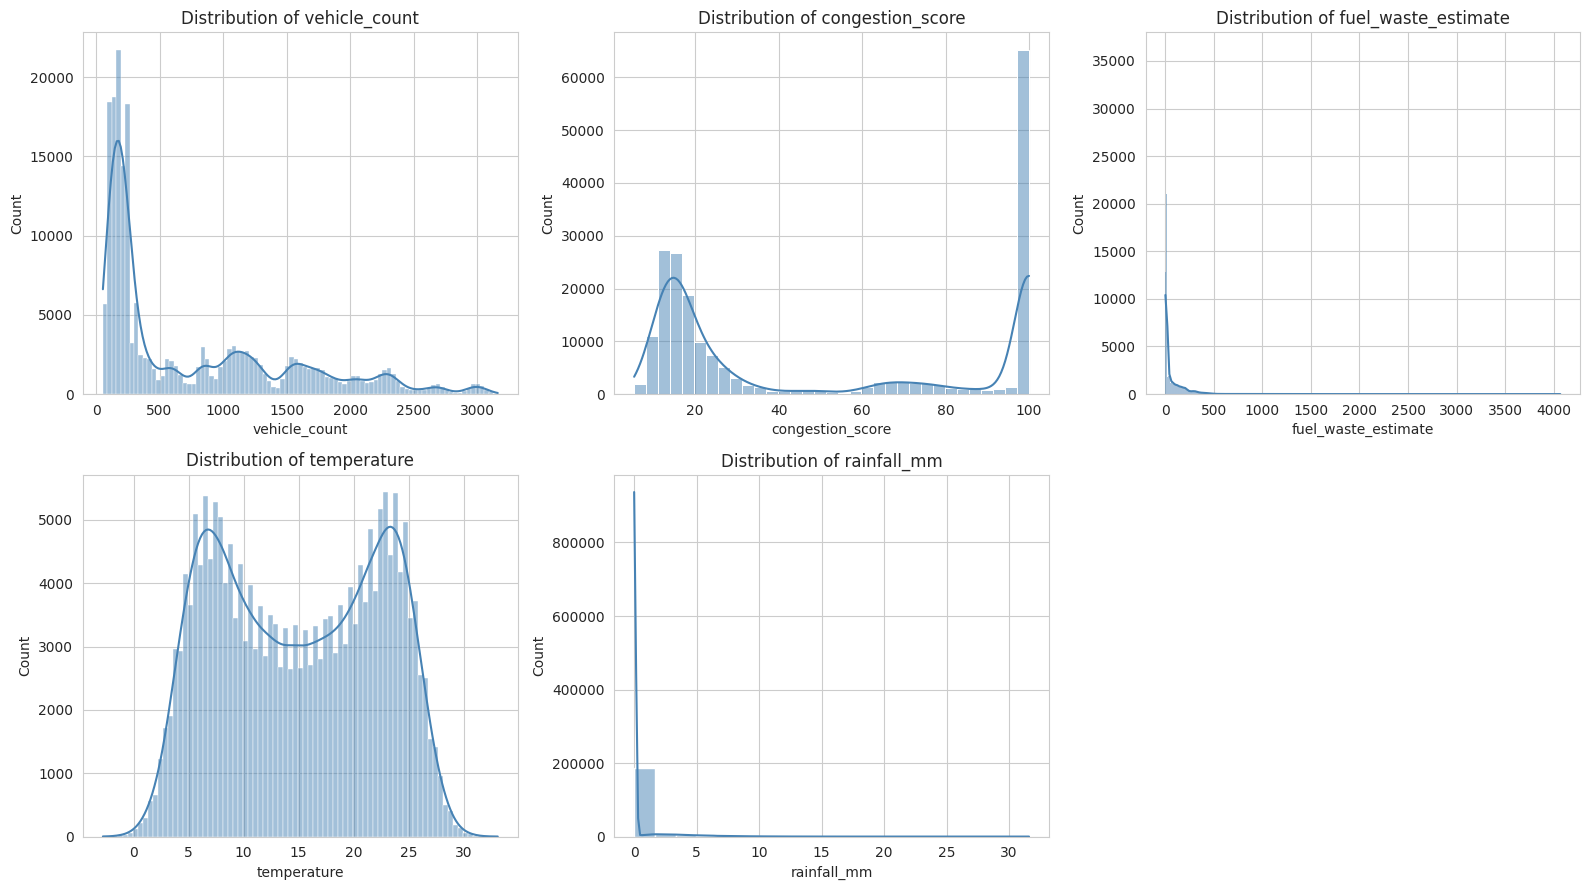

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, key_numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

# hide the unused 6th subplot
axes[-1].axis("off")
plt.tight_layout()
plt.show()


**Interpretation:** The histograms with KDE (smoothed density curve) show whether each variable is
roughly symmetric, skewed, or has a long tail. `vehicle_count`, `congestion_score`, and
`fuel_waste_estimate` typically show right-skew (many low/medium values and fewer very high ones),
which is common for traffic-volume type data.


### 1.9 Boxplots to inspect outliers


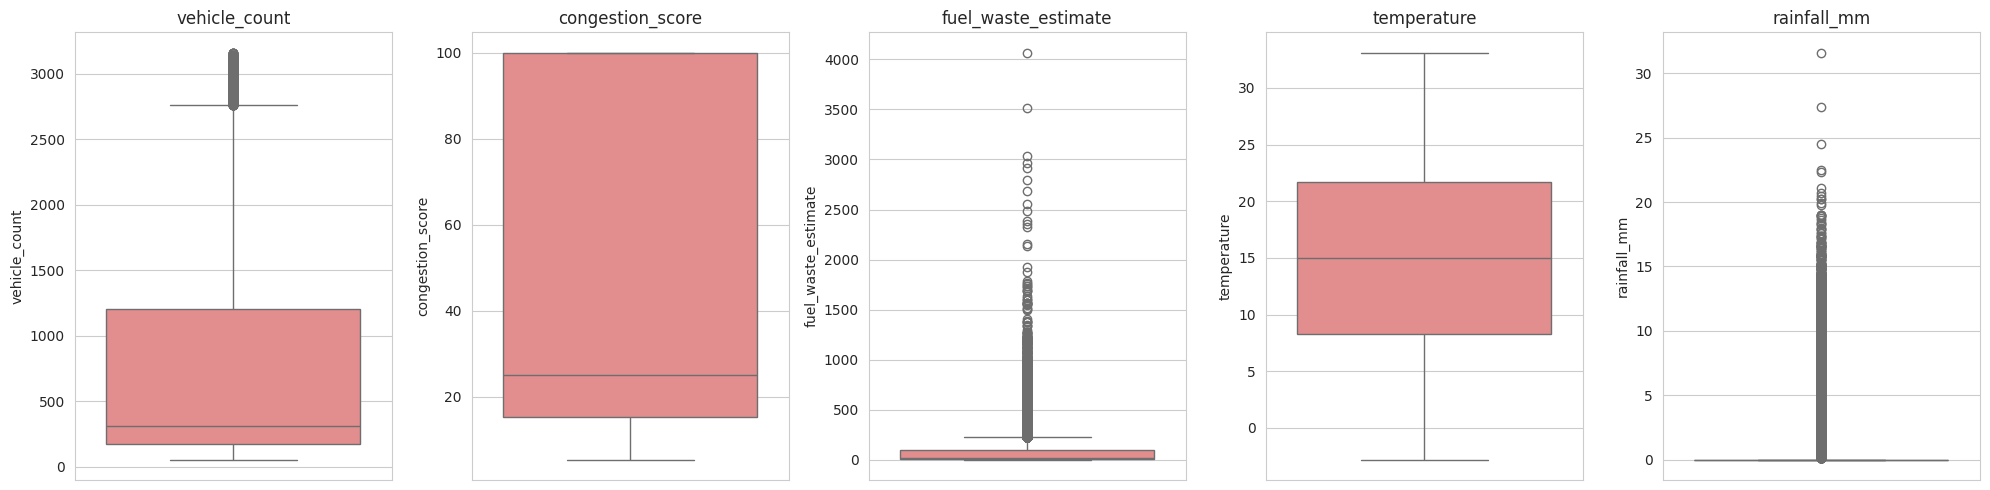

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, key_numeric_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Interpretation:** Points above the upper whisker (or below the lower whisker) of each boxplot are
candidate outliers. A wide box with many points above it (as in `fuel_waste_estimate`) suggests a
right-skewed variable with a number of unusually high readings, rather than necessarily "bad data".


### 1.10 Count plots for categorical variables


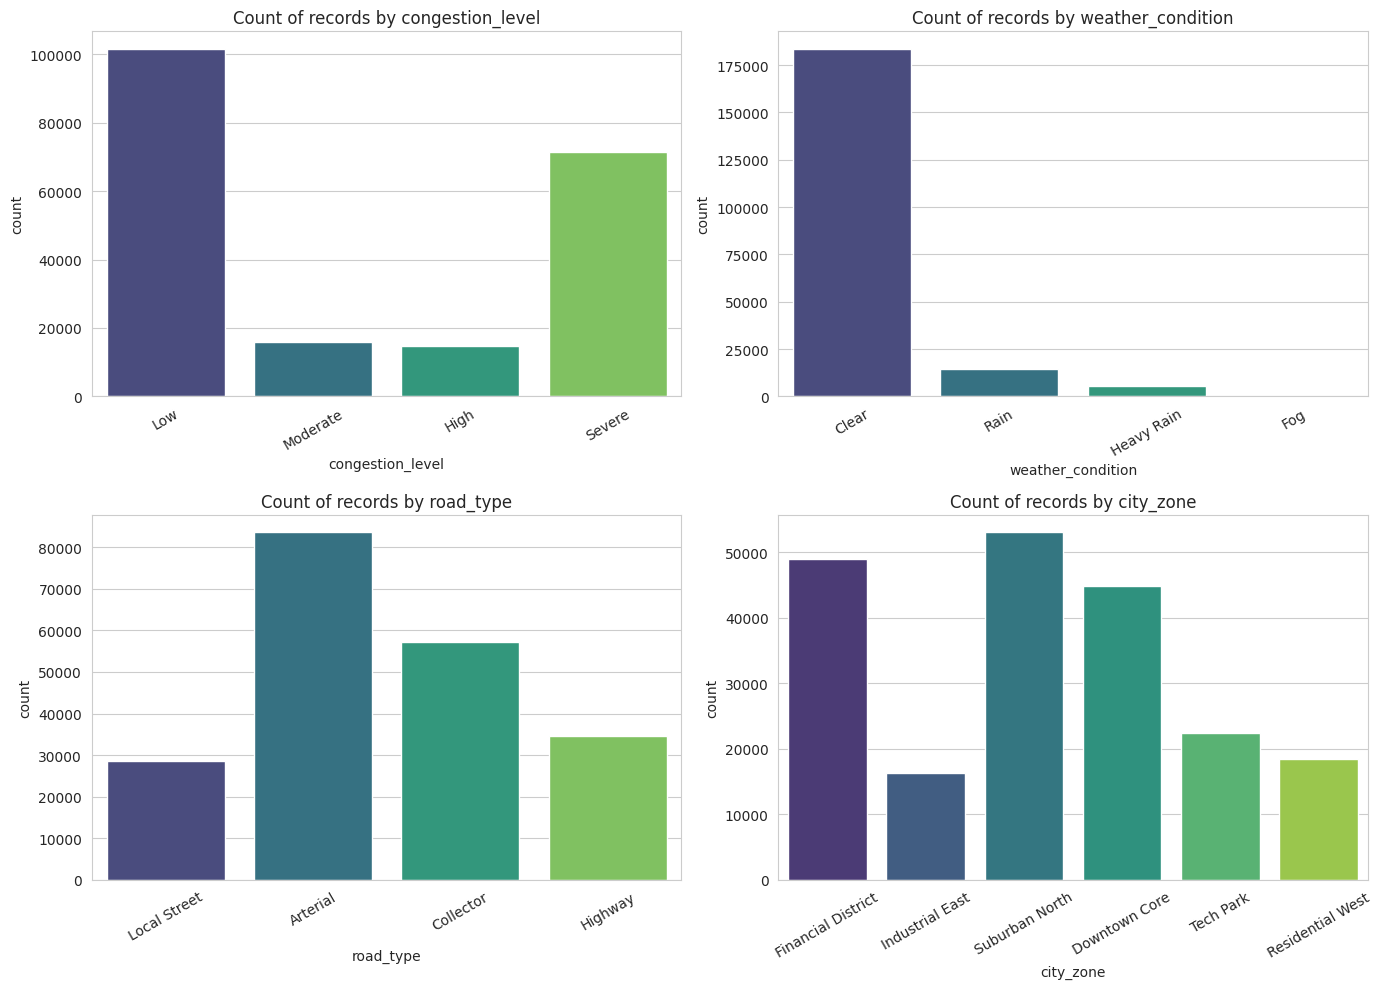

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

order_congestion = ["Low", "Moderate", "High", "Severe"]
plot_specs = [
    ("congestion_level", order_congestion),
    ("weather_condition", None),
    ("road_type", None),
    ("city_zone", None),
]

for ax, (col, order) in zip(axes, plot_specs):
    sns.countplot(data=df, x=col, order=order, ax=ax, palette="viridis")
    ax.set_title(f"Count of records by {col}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


**Interpretation:** Most records fall under "Clear" weather and "Arterial"/"Collector" road types,
and the "Low" congestion level is the most common class. This class imbalance is important to keep
in mind for the classification practical later.


### 1.11 Hourly traffic-volume patterns


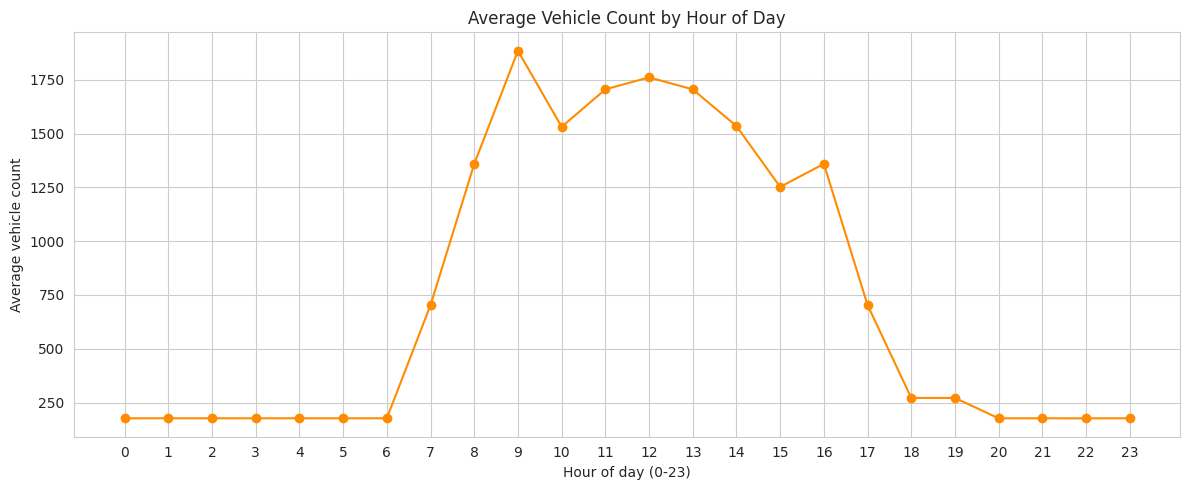

In [ ]:
hourly_avg = df.groupby("hour")["vehicle_count"].mean()

plt.figure(figsize=(12, 5))
hourly_avg.plot(kind="line", marker="o", color="darkorange")
plt.title("Average Vehicle Count by Hour of Day")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("Average vehicle count")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


**Interpretation:** This line chart reveals the daily traffic rhythm - typically showing peaks during
morning and evening rush hours and lower volumes late at night. This is purely a descriptive
observation about this dataset, not a universal law.


### 1.12 Weekday vs weekend comparison


In [ ]:
weekday_weekend_avg = df.groupby("is_weekend")["vehicle_count"].agg(["mean", "median", "std", "count"])
weekday_weekend_avg.index = weekday_weekend_avg.index.map({0: "Weekday", 1: "Weekend"})
weekday_weekend_avg


,mean,median,std,count
is_weekend,,,,
Weekday,838.265499,339.0,805.663641,146400
Weekend,524.191944,208.0,543.900552,57600


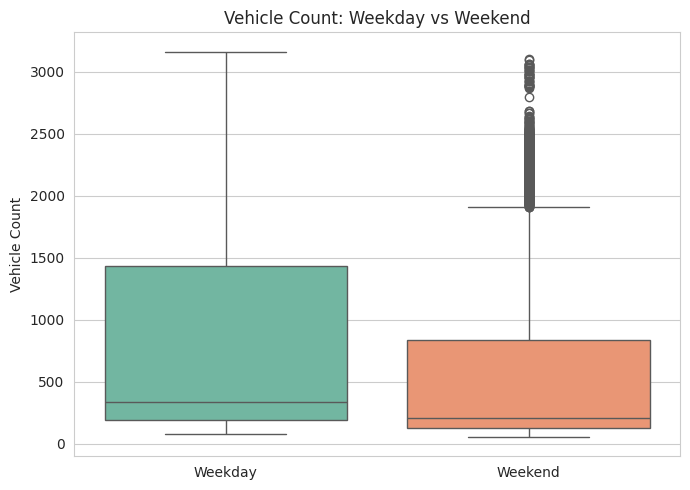

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x=df["is_weekend"].map({0: "Weekday", 1: "Weekend"}), y="vehicle_count", palette="Set2")
plt.title("Vehicle Count: Weekday vs Weekend")
plt.xlabel("")
plt.ylabel("Vehicle Count")
plt.tight_layout()
plt.show()


**Interpretation:** The table and boxplot together show whether traffic volume tends to differ between
weekdays and weekends in this dataset. A formal statistical test of this difference is performed later
in Practical 5 (independent samples t-test).


### 1.13 Traffic across weather conditions and road types


In [ ]:
weather_summary = df.groupby("weather_condition")["vehicle_count"].agg(["mean", "median", "std", "count"])
road_summary = df.groupby("road_type")["vehicle_count"].agg(["mean", "median", "std", "count"])
print("By weather condition:")
display(weather_summary)
print("\nBy road type:")
display(road_summary)


By weather condition:


,mean,median,std,count
weather_condition,,,,
Clear,750.648325,308.0,755.722773,183664
Fog,718.639640,250.5,726.966016,222
Heavy Rain,749.084987,321.5,742.990260,5542
Rain,736.857260,301.0,744.303738,14572



By road type:


,mean,median,std,count
road_type,,,,
Arterial,842.816380,328.0,791.718226,83640
Collector,526.640126,211.0,497.638832,57120
Highway,1063.981488,426.0,988.591743,34680
Local Street,540.679307,213.0,510.379608,28560


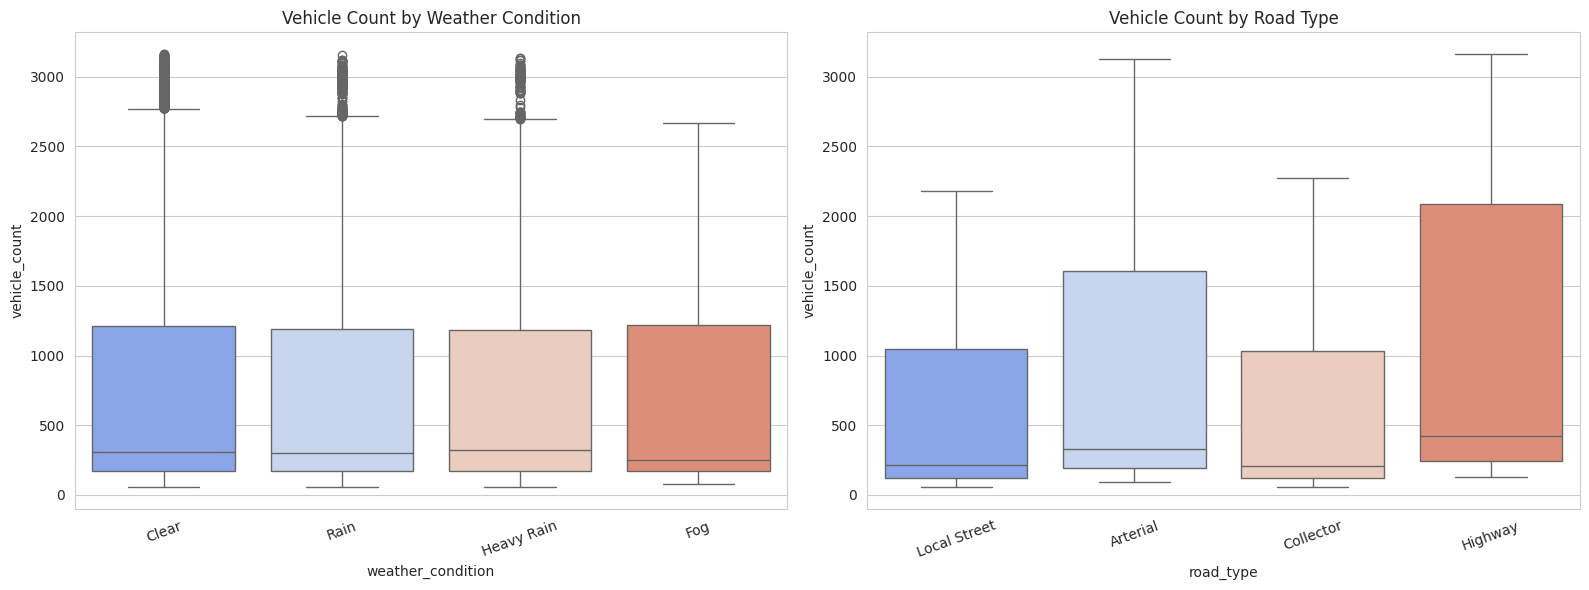

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x="weather_condition", y="vehicle_count", ax=axes[0], palette="coolwarm")
axes[0].set_title("Vehicle Count by Weather Condition")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="road_type", y="vehicle_count", ax=axes[1], palette="coolwarm")
axes[1].set_title("Vehicle Count by Road Type")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


**Interpretation:** Road type differences are usually much larger than weather differences for vehicle
count, since a Highway is built to carry far more traffic than a Local Street regardless of weather.
Any apparent difference here is descriptive only; Practical 5 tests some of these relationships
formally.


### 1.14 Correlation heatmap (numerical features)


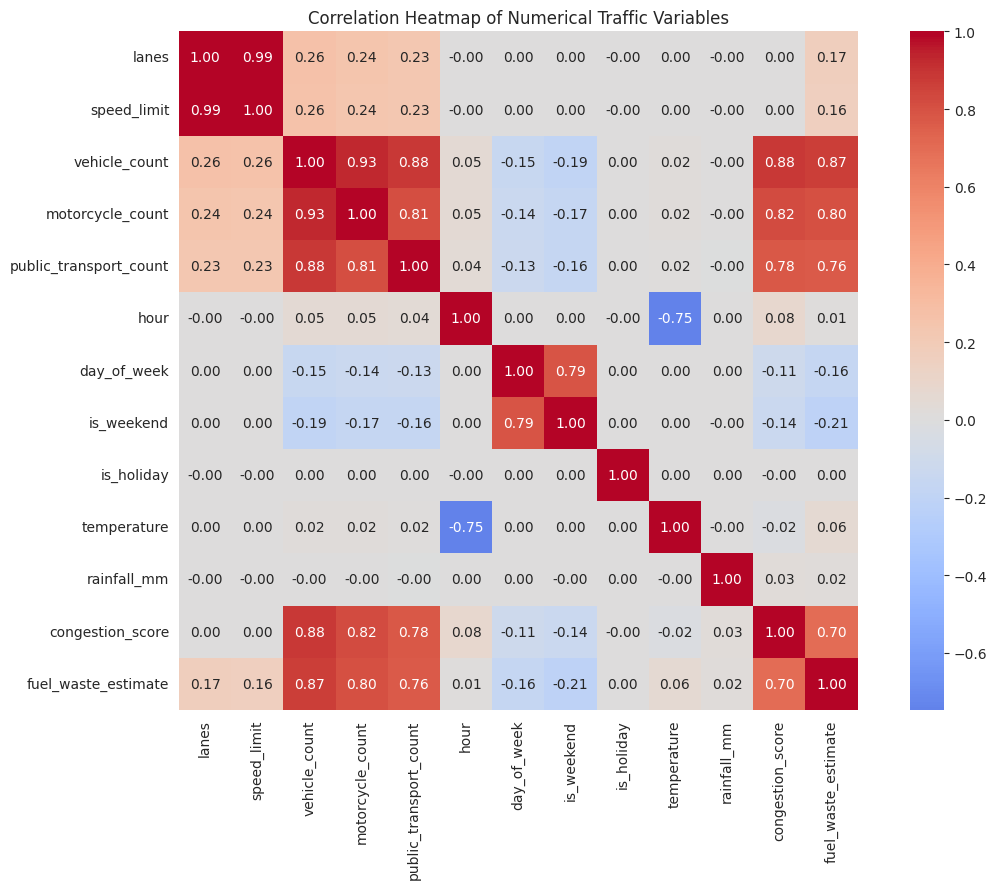

In [ ]:
numeric_cols_for_corr = [
    "lanes", "speed_limit", "vehicle_count", "motorcycle_count", "public_transport_count",
    "hour", "day_of_week", "is_weekend", "is_holiday", "temperature", "rainfall_mm",
    "congestion_score", "fuel_waste_estimate",
]

corr_matrix = df[numeric_cols_for_corr].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Numerical Traffic Variables")
plt.tight_layout()
plt.show()


**Interpretation:** `vehicle_count`, `motorcycle_count`, and `public_transport_count` are all
strongly positively correlated with `congestion_score` - more vehicles on the road is associated with
higher congestion in this dataset. `speed_limit`, `lanes`, `temperature`, and `rainfall_mm` show weak
correlation with congestion here. **Correlation only measures association, not causation** - we
cannot conclude from this heatmap alone that, say, rainfall has no causal effect on congestion.


### 1.15 Scatter plots: vehicle count vs congestion score and fuel waste


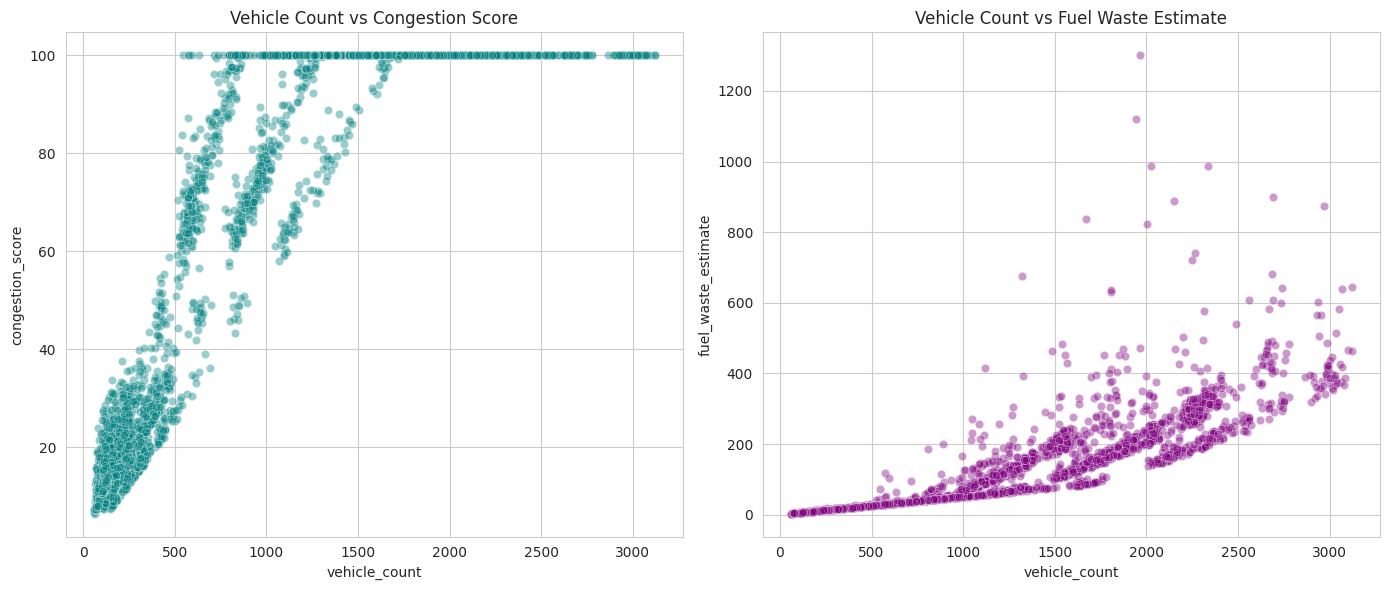

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(data=df.sample(5000, random_state=RANDOM_STATE), x="vehicle_count", y="congestion_score",
                 alpha=0.4, ax=axes[0], color="teal")
axes[0].set_title("Vehicle Count vs Congestion Score")

sns.scatterplot(data=df.sample(5000, random_state=RANDOM_STATE), x="vehicle_count", y="fuel_waste_estimate",
                 alpha=0.4, ax=axes[1], color="purple")
axes[1].set_title("Vehicle Count vs Fuel Waste Estimate")

plt.tight_layout()
plt.show()


**Interpretation:** Both scatter plots show a clear upward trend - more vehicles tend to come with
higher congestion scores and higher estimated fuel waste. A sample of 5,000 points (not the full
204,000) is plotted purely to keep the chart readable; the underlying statistics in later sections
still use the full dataset unless stated otherwise.


### 1.16 Grouped summary tables


In [ ]:
print("Average congestion_score by hour (first 12 hours shown):")
display(df.groupby("hour")["congestion_score"].mean().round(2).head(12))

print("\nAverage congestion_score by weather_condition:")
display(df.groupby("weather_condition")["congestion_score"].mean().round(2))

print("\nAverage congestion_score by road_type:")
display(df.groupby("road_type")["congestion_score"].mean().round(2))

print("\nAverage vehicle_count by congestion_level:")
display(df.groupby("congestion_level")["vehicle_count"].mean().round(2).sort_values())


Average congestion_score by hour (first 12 hours shown):


,congestion_score
hour,
0,15.47
1,15.40
2,15.52
3,15.49
4,15.46
5,15.44
6,15.50
7,60.52
8,88.64



Average congestion_score by weather_condition:


,congestion_score
weather_condition,
Clear,49.63
Fog,54.08
Heavy Rain,56.88
Rain,52.08



Average congestion_score by road_type:


,congestion_score
road_type,
Arterial,50.51
Collector,49.54
Highway,49.56
Local Street,50.02



Average vehicle_count by congestion_level:


,vehicle_count
congestion_level,
Low,181.06
Moderate,366.24
High,818.54
Severe,1629.45


### 1.17 Summary of EDA findings

- The dataset has **no fully duplicated rows** and **no duplicated `record_id`s** (verified above).
- Traffic volume follows a clear **daily rhythm** tied to `hour`, and differs noticeably by `road_type`.
- `vehicle_count`, `motorcycle_count`, and `public_transport_count` are the variables most strongly
  associated with `congestion_score`.
- The `congestion_level` classes are **imbalanced** ("Low" is the most common class), which will be
  important when evaluating the classification model in Practical 8.
- All of the above are **descriptive observations about this dataset**, not causal claims.


## Practical 2: Data Preprocessing

**Aim:** Clean and prepare the data for statistical analysis and machine learning, while keeping the
original `df` untouched for descriptive/EDA purposes.

**Concept:** Preprocessing for *description* (EDA) and preprocessing for *machine learning* are not
the same thing:
- For EDA, we mostly just need valid values and correct data types - we can look at the **whole**
  dataset together.
- For ML, we must avoid **data leakage**: any transformation that "learns" something from the data
  (like filling missing values with a mean, encoding categories, or scaling numbers) must be learned
  **only from the training set** and then applied unchanged to the test set. Otherwise the model gets
  an unfair sneak-peek at the test data during training, which makes evaluation metrics overly
  optimistic.

We create a separate `df_clean` DataFrame below so that `df` stays available for any further
descriptive analysis.


### 2.1 Convert timestamp to datetime


In [ ]:
df_clean = df.copy()
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"], errors="coerce")
print("Rows where timestamp failed to parse:", df_clean["timestamp"].isna().sum())
df_clean[["timestamp"]].head()


Rows where timestamp failed to parse: 0


,timestamp
0,2026-01-01 00:00:00
1,2026-01-01 01:00:00
2,2026-01-01 02:00:00
3,2026-01-01 03:00:00
4,2026-01-01 04:00:00


### 2.2 Remove duplicate rows (if any)


In [ ]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
after = len(df_clean)
print(f"Removed {before - after} duplicate rows (had {before}, now {after}).")


Removed 0 duplicate rows (had 204000, now 204000).


### 2.3 Handle missing values


In [ ]:
numeric_cols_all = df_clean.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols_all = df_clean.select_dtypes(include=["object"]).columns.tolist()

print("Missing values BEFORE handling:")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

# Numerical columns: fill with the median (robust to outliers)
for col in numeric_cols_all:
    if df_clean[col].isna().sum() > 0:
        median_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_value)

# Categorical columns: fill with the mode (most frequent category)
for col in categorical_cols_all:
    if df_clean[col].isna().sum() > 0:
        mode_value = df_clean[col].mode().iloc[0]
        df_clean[col] = df_clean[col].fillna(mode_value)

print("\nMissing values AFTER handling:", df_clean.isna().sum().sum())


Missing values BEFORE handling:
Series([], dtype: int64)

Missing values AFTER handling: 0


**Note:** If the dataset genuinely has zero missing values, the loops above simply do nothing - they
are written defensively so the notebook still works correctly on a slightly different export of the
same dataset.


### 2.4 Validate numerical columns for impossible/inconsistent values


In [ ]:
checks = {
    "negative vehicle_count": (df_clean["vehicle_count"] < 0).sum(),
    "negative motorcycle_count": (df_clean["motorcycle_count"] < 0).sum(),
    "negative public_transport_count": (df_clean["public_transport_count"] < 0).sum(),
    "non-positive speed_limit": (df_clean["speed_limit"] <= 0).sum(),
    "non-positive lanes": (df_clean["lanes"] <= 0).sum(),
    "negative rainfall_mm": (df_clean["rainfall_mm"] < 0).sum(),
    "congestion_score outside [0, 100]": (~df_clean["congestion_score"].between(0, 100)).sum(),
    "hour outside [0, 23]": (~df_clean["hour"].between(0, 23)).sum(),
    "day_of_week outside [0, 6]": (~df_clean["day_of_week"].between(0, 6)).sum(),
}
for description, count in checks.items():
    print(f"{description}: {count} row(s)")


negative vehicle_count: 0 row(s)
negative motorcycle_count: 0 row(s)
negative public_transport_count: 0 row(s)
non-positive speed_limit: 0 row(s)
non-positive lanes: 0 row(s)
negative rainfall_mm: 0 row(s)
congestion_score outside [0, 100]: 0 row(s)
hour outside [0, 23]: 0 row(s)
day_of_week outside [0, 6]: 0 row(s)


### 2.5 Validate binary columns (is_weekend, is_holiday)


In [ ]:
print("Unique values in is_weekend:", sorted(df_clean["is_weekend"].unique()))
print("Unique values in is_holiday:", sorted(df_clean["is_holiday"].unique()))


Unique values in is_weekend: [np.int64(0), np.int64(1)]
Unique values in is_holiday: [np.int64(0), np.int64(1)]


### 2.6 Outlier inspection using the IQR method


In [ ]:
def iqr_outlier_report(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((series < lower) | (series > upper)).sum()
    return lower, upper, n_outliers

for col in ["vehicle_count", "motorcycle_count", "public_transport_count", "congestion_score", "fuel_waste_estimate"]:
    lower, upper, n_outliers = iqr_outlier_report(df_clean[col])
    pct = round(100 * n_outliers / len(df_clean), 2)
    print(f"{col}: IQR bounds = [{lower:.2f}, {upper:.2f}] -> {n_outliers} outlier rows ({pct}%)")


vehicle_count: IQR bounds = [-1384.50, 2763.50] -> 3036 outlier rows (1.49%)
motorcycle_count: IQR bounds = [-135.50, 268.50] -> 7391 outlier rows (3.62%)
public_transport_count: IQR bounds = [-39.50, 76.50] -> 10776 outlier rows (5.28%)
congestion_score: IQR bounds = [-112.00, 227.20] -> 0 outlier rows (0.0%)
fuel_waste_estimate: IQR bounds = [-125.35, 232.78] -> 17388 outlier rows (8.52%)


**Interpretation:** These "outliers" are values outside 1.5x the interquartile range, which is a
standard statistical rule of thumb, not proof that a value is wrong. Traffic data is naturally
right-skewed (occasional very busy hours), so many of these points are **genuine high-traffic
observations**, not data errors. We therefore **keep** these rows rather than deleting them -
removing real high-congestion events would bias the analysis towards only "normal" traffic.


### 2.7 Extract/validate hour, weekday, month, and weekend features from timestamp


In [ ]:
df_clean["hour_from_ts"] = df_clean["timestamp"].dt.hour
df_clean["day_of_week_from_ts"] = df_clean["timestamp"].dt.dayofweek
df_clean["month_from_ts"] = df_clean["timestamp"].dt.month
df_clean["is_weekend_from_ts"] = (df_clean["day_of_week_from_ts"] >= 5).astype(int)

hour_match = (df_clean["hour_from_ts"] == df_clean["hour"]).mean() * 100
dow_match = (df_clean["day_of_week_from_ts"] == df_clean["day_of_week"]).mean() * 100

print(f"hour column matches timestamp-derived hour in {hour_match:.1f}% of rows")
print(f"day_of_week column matches timestamp-derived day_of_week in {dow_match:.1f}% of rows")


hour column matches timestamp-derived hour in 100.0% of rows
day_of_week column matches timestamp-derived day_of_week in 100.0% of rows


**Interpretation:** If the match percentages are at or near 100%, the existing `hour` and
`day_of_week` columns are already consistent with the `timestamp` column, so we can safely keep using
the original columns for the rest of the notebook (they are simpler and already validated).


### 2.8 Encode categorical variables (one-hot encoding)


In [ ]:
# Simple demonstration of one-hot encoding for descriptive purposes.
# NOTE: for the actual ML models later (Practicals 7 and 8), encoding is done
# INSIDE a scikit-learn Pipeline fitted only on the training data, to avoid leakage.
demo_encoded = pd.get_dummies(df_clean[["road_type", "weather_condition"]], drop_first=True)
demo_encoded.head()


,road_type_Collector,road_type_Highway,road_type_Local Street,weather_condition_Fog,weather_condition_Heavy Rain,weather_condition_Rain
0,False,False,True,False,False,False
1,False,False,True,False,False,False
2,False,False,True,False,False,False
3,False,False,True,False,False,False
4,False,False,True,False,False,False


### 2.9 Scaling numerical features


In [ ]:
# A demonstration only - real scaling for ML models happens inside a Pipeline (see Practicals 7-8)
# so that the scaler is fit on the training set only.
from sklearn.preprocessing import StandardScaler

demo_scaler = StandardScaler()
demo_scaled = demo_scaler.fit_transform(df_clean[["vehicle_count", "speed_limit"]].head(5))
print("Example of scaled values (first 5 rows, for illustration only):")
print(demo_scaled)


Example of scaled values (first 5 rows, for illustration only):
[[-0.30618622  0.        ]
 [-1.32680694  0.        ]
 [ 1.73505523  0.        ]
 [-0.30618622  0.        ]
 [ 0.20412415  0.        ]]


### 2.10 EDA preprocessing vs ML preprocessing - summary

| | For EDA / description | For Machine Learning |
|---|---|---|
| Missing values | Can describe or visualize with missing data present | Must fill in first (and only using training-set statistics) |
| Encoding | Not required - can group by category directly | Required - models need numbers, fit only on training data |
| Scaling | Not required | Required for some models; fit only on training data |
| Dataset used | The full dataset at once | Split into train/test **before** fitting any transformer |

From this point on, `df_clean` is the cleaned DataFrame used for sampling, hypothesis testing, and
modelling, while `df` remains available for any further descriptive look-back.


## Practical 3: Distribution Sampling and the Central Limit Theorem

### Part A: Distribution Sampling

**Aim:** Understand the difference between a population and a sample, and see how a random sample's
statistics compare to the population's statistics.

**Concept:**
- **Population** = every single observation we have (here, all rows of `df_clean`).
- **Sample** = a smaller, randomly chosen subset of the population.
- **Random sampling** = every observation has an equal chance of being chosen, which helps the sample
  represent the population fairly.
- **Sampling bias** = what happens when the way we pick a sample makes certain kinds of observations
  more likely to be included than others (e.g. only sampling from one city zone) - this makes the
  sample statistics misleading.


In [ ]:
import numpy as np

np.random.seed(RANDOM_STATE)  # fixed seed for reproducibility

population = df_clean["vehicle_count"]
population_mean = population.mean()
population_std = population.std()

print(f"Population size: {len(population)}")
print(f"Population mean: {population_mean:.2f}")
print(f"Population std:  {population_std:.2f}")


Population size: 204000
Population mean: 749.59
Population std:  754.54


In [ ]:
sample_size = 200
sample = population.sample(sample_size, random_state=RANDOM_STATE)

print(f"Sample size: {sample_size}")
print(f"Sample mean: {sample.mean():.2f}")
print(f"Sample std:  {sample.std():.2f}")
print(f"Difference in means: {abs(population_mean - sample.mean()):.2f}")


Sample size: 200
Sample mean: 799.00
Sample std:  814.15
Difference in means: 49.42


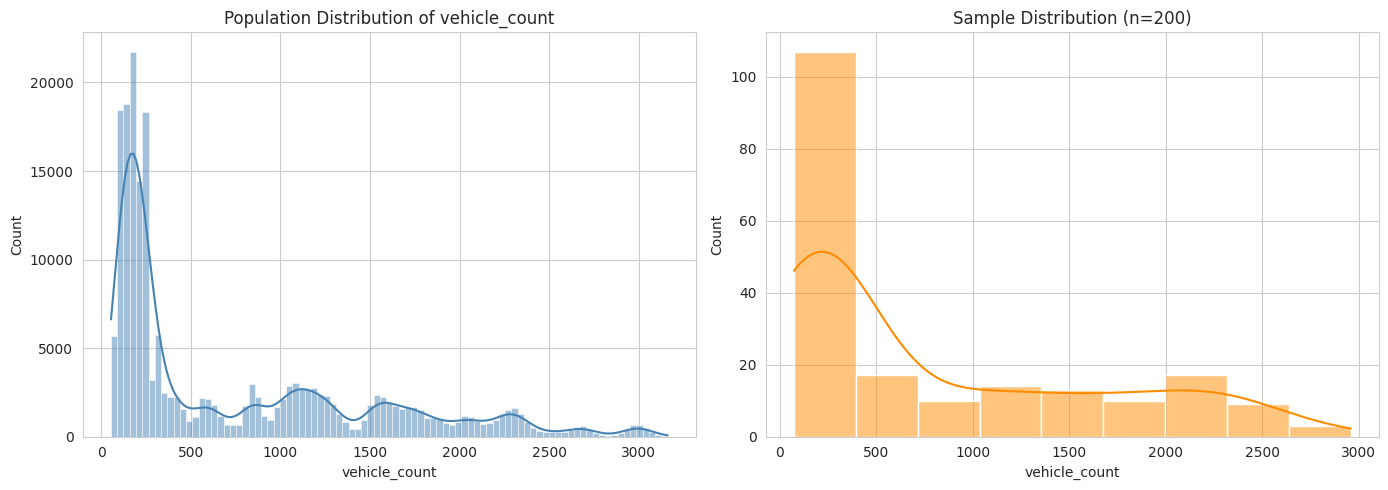

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(population, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Population Distribution of vehicle_count")

sns.histplot(sample, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title(f"Sample Distribution (n={sample_size})")

plt.tight_layout()
plt.show()


**Interpretation:** A single random sample's shape is noisier (because it has far fewer points) but
should resemble the overall shape of the population distribution, and its mean/std should be fairly
close to the population's mean/std if the sample is large enough and truly random.


In [ ]:
# Repeat sampling at multiple sample sizes and compare mean/std to the population
sample_sizes = [10, 50, 200, 1000, 5000]
rows = []
for n in sample_sizes:
    s = population.sample(n, random_state=RANDOM_STATE)
    rows.append({"sample_size": n, "sample_mean": s.mean(), "sample_std": s.std(),
                 "mean_diff_from_population": abs(s.mean() - population_mean)})

sampling_comparison = pd.DataFrame(rows)
sampling_comparison


,sample_size,sample_mean,sample_std,mean_diff_from_population
0,10,720.000,647.375556,29.585907
1,50,752.140,789.096047,2.554093
2,200,799.005,814.149786,49.419093
3,1000,791.814,776.506980,42.228093
4,5000,755.057,752.749699,5.471093


**Interpretation:** As the sample size grows, the sample mean generally gets **closer** to the true
population mean, and the sample's std gets closer to the population's std. This is the intuition
behind why larger samples are more trustworthy.


### Part B: Central Limit Theorem (CLT)

**Concept:** The Central Limit Theorem says that if we repeatedly draw random samples of a reasonably
large size from *any* population and compute the **mean of each sample**, the distribution of those
sample means will look approximately **Normal (bell-shaped)** - even if the original population
distribution (like our right-skewed `vehicle_count`) is not Normal at all.

Importantly, CLT is a statement about the distribution of **sample means**, not about individual
observations - individual `vehicle_count` values stay right-skewed no matter how many samples we take.


In [ ]:
def simulate_sample_means(data, sample_size, n_simulations, seed):
    rng = np.random.default_rng(seed)
    means = np.empty(n_simulations)
    data_array = data.values
    for i in range(n_simulations):
        sample_idx = rng.choice(len(data_array), size=sample_size, replace=False)
        means[i] = data_array[sample_idx].mean()
    return means

n_simulations = 1000
sample_means_30 = simulate_sample_means(population, sample_size=30, n_simulations=n_simulations, seed=RANDOM_STATE)

print(f"Mean of the {n_simulations} sample means (n=30 each): {sample_means_30.mean():.2f}")
print(f"Std of the sample means (this is the 'standard error'): {sample_means_30.std():.2f}")
print(f"Population mean for comparison: {population_mean:.2f}")


Mean of the 1000 sample means (n=30 each): 746.41
Std of the sample means (this is the 'standard error'): 142.73
Population mean for comparison: 749.59


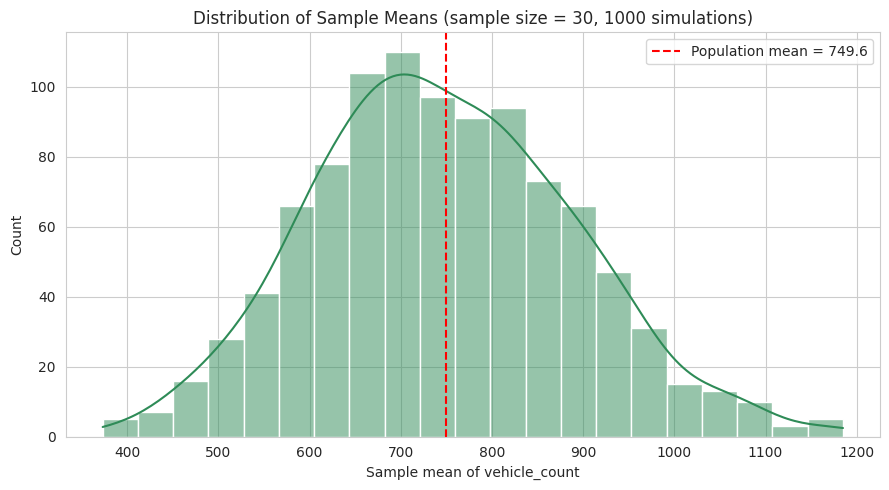

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(sample_means_30, kde=True, color="seagreen")
plt.axvline(population_mean, color="red", linestyle="--", label=f"Population mean = {population_mean:.1f}")
plt.title("Distribution of Sample Means (sample size = 30, 1000 simulations)")
plt.xlabel("Sample mean of vehicle_count")
plt.legend()
plt.tight_layout()
plt.show()


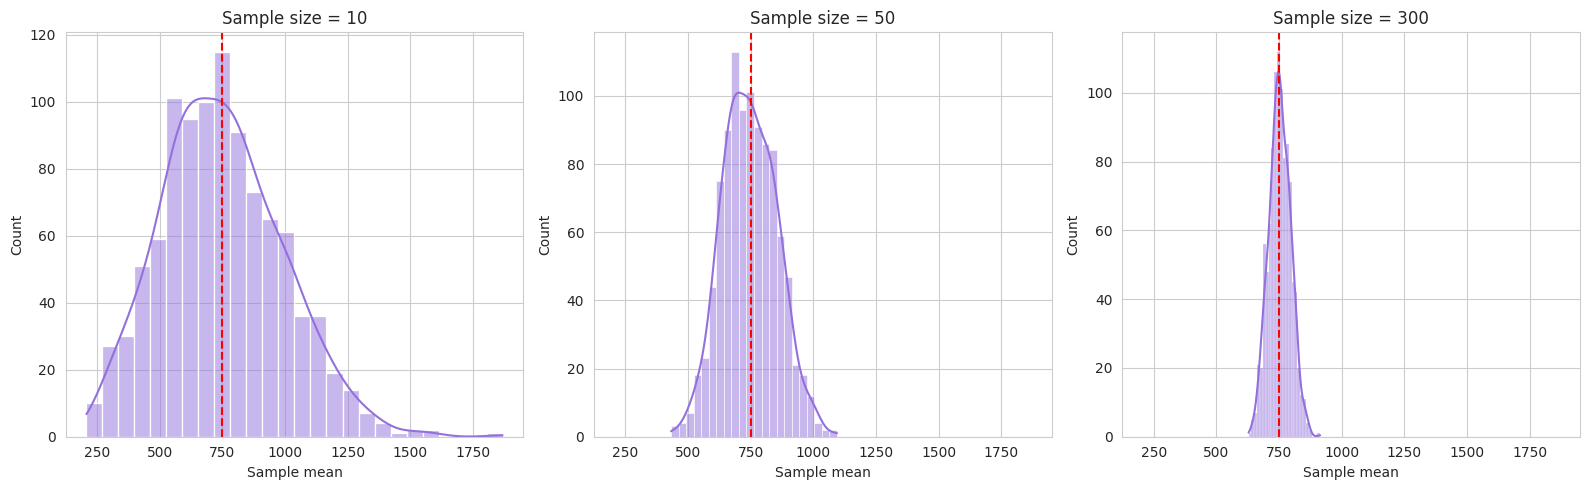

In [ ]:
# Show how the sample-mean distribution gets narrower (more concentrated) as sample size grows
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, n in zip(axes, [10, 50, 300]):
    means_n = simulate_sample_means(population, sample_size=n, n_simulations=n_simulations, seed=RANDOM_STATE)
    sns.histplot(means_n, kde=True, ax=ax, color="mediumpurple")
    ax.axvline(population_mean, color="red", linestyle="--")
    ax.set_title(f"Sample size = {n}")
    ax.set_xlabel("Sample mean")

plt.tight_layout()
plt.show()


**Interpretation:** As the sample size used for each simulated sample increases (10 -> 50 -> 300), the
distribution of sample means becomes **narrower and more tightly clustered** around the true
population mean, and more clearly bell-shaped. This matches the CLT prediction.


In [ ]:
# Theoretical standard error = population_std / sqrt(sample_size)
for n in [10, 30, 50, 300]:
    theoretical_se = population_std / np.sqrt(n)
    simulated_means = simulate_sample_means(population, sample_size=n, n_simulations=n_simulations, seed=RANDOM_STATE)
    empirical_se = simulated_means.std()
    print(f"n={n:>4}: theoretical SE = {theoretical_se:7.3f}  |  empirical SE (from simulation) = {empirical_se:7.3f}")


n=  10: theoretical SE = 238.607  |  empirical SE (from simulation) = 242.888
n=  30: theoretical SE = 137.760  |  empirical SE (from simulation) = 142.733
n=  50: theoretical SE = 106.708  |  empirical SE (from simulation) = 108.251
n= 300: theoretical SE =  43.564  |  empirical SE (from simulation) =  42.893


**Interpretation in simple English:** The "standard error" tells us how much sample means typically
bounce around the true population mean. The formula `population_std / sqrt(n)` (theoretical) closely
matches what we actually observe from repeated simulated sampling (empirical), which confirms the CLT
in practice. Bigger samples -> smaller standard error -> more reliable sample means. This does **not**
mean individual `vehicle_count` observations become Normally distributed; only the **means of
samples** do.


## Practical 4: Correlation and Covariance

**Aim:** Measure the strength and direction of linear relationships between traffic variables.

**Concept:**
- **Covariance** tells us whether two variables move in the same direction (positive), opposite
  directions (negative), or show no consistent pattern (near zero) - but its size depends on the
  units of the variables, which makes it hard to compare across variable pairs.
- **Pearson correlation** is covariance rescaled to always fall between -1 and +1, which makes it
  much easier to interpret and compare. A value near +1 means a strong positive linear relationship,
  near -1 means a strong negative one, and near 0 means little to no linear relationship.


In [ ]:
corr_cols = ["vehicle_count", "motorcycle_count", "public_transport_count", "speed_limit",
             "lanes", "temperature", "rainfall_mm", "congestion_score", "fuel_waste_estimate"]

pearson_corr = df_clean[corr_cols].corr(method="pearson")
pearson_corr.round(3)


,vehicle_count,motorcycle_count,public_transport_count,speed_limit,lanes,temperature,rainfall_mm,congestion_score,fuel_waste_estimate
vehicle_count,1.000,0.926,0.879,0.259,0.265,0.020,-0.003,0.885,0.867
motorcycle_count,0.926,1.000,0.814,0.239,0.245,0.019,-0.002,0.819,0.805
public_transport_count,0.879,0.814,1.000,0.230,0.235,0.017,-0.005,0.776,0.762
speed_limit,0.259,0.239,0.230,1.000,0.991,0.000,-0.001,0.000,0.161
lanes,0.265,0.245,0.235,0.991,1.000,0.000,-0.001,0.002,0.168
temperature,0.020,0.019,0.017,0.000,0.000,1.000,-0.000,-0.022,0.062
rainfall_mm,-0.003,-0.002,-0.005,-0.001,-0.001,-0.000,1.000,0.031,0.024
congestion_score,0.885,0.819,0.776,0.000,0.002,-0.022,0.031,1.000,0.697
fuel_waste_estimate,0.867,0.805,0.762,0.161,0.168,0.062,0.024,0.697,1.000


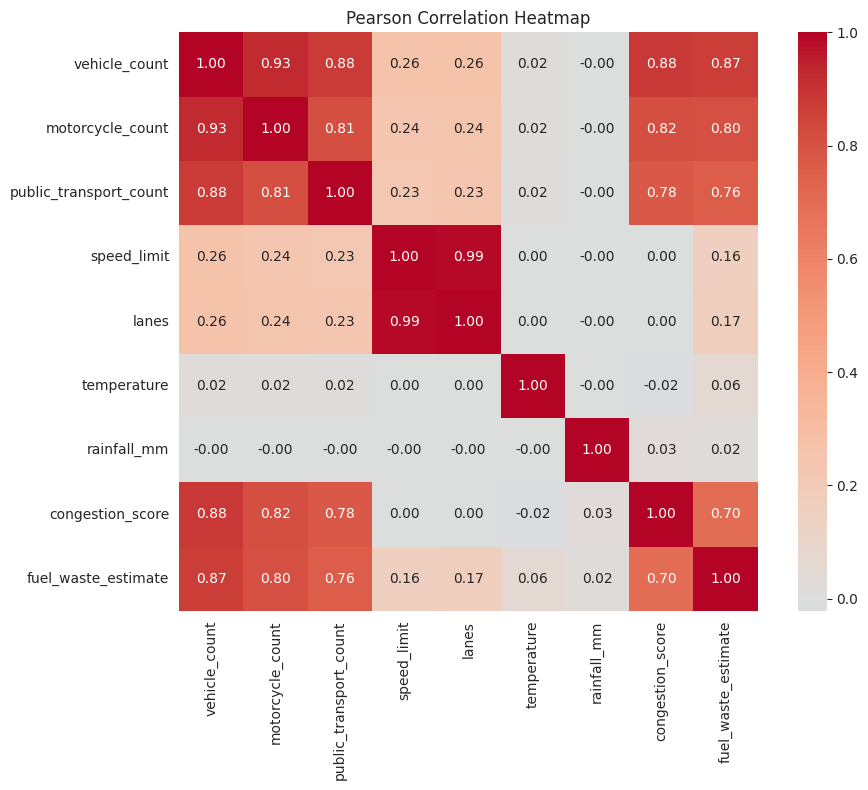

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:
covariance_matrix = df_clean[corr_cols].cov()
covariance_matrix.round(2)


,vehicle_count,motorcycle_count,public_transport_count,speed_limit,lanes,temperature,rainfall_mm,congestion_score,fuel_waste_estimate
vehicle_count,569334.19,56955.81,17085.88,3436.87,145.12,110.29,-2.93,25898.51,72915.83
motorcycle_count,56955.81,6640.52,1710.66,343.40,14.50,11.44,-0.21,2589.89,7311.49
public_transport_count,17085.88,1710.66,664.30,104.20,4.39,3.31,-0.19,775.91,2191.49
speed_limit,3436.87,343.40,104.20,310.11,12.68,0.04,-0.03,0.31,315.80
lanes,145.12,14.50,4.39,12.68,0.53,0.00,-0.00,0.05,13.61
temperature,110.29,11.44,3.31,0.04,0.00,53.98,-0.00,-6.13,50.44
rainfall_mm,-2.93,-0.21,-0.19,-0.03,-0.00,-0.00,2.25,1.78,4.07
congestion_score,25898.51,2589.89,775.91,0.31,0.05,-6.13,1.78,1505.33,3016.35
fuel_waste_estimate,72915.83,7311.49,2191.49,315.80,13.61,50.44,4.07,3016.35,12436.69


**Interpretation:**
- `vehicle_count` has the **strongest positive correlation** with `congestion_score`
  (association, not proof of a one-way cause) - as vehicle counts rise, congestion scores tend to
  rise too in this dataset.
- `speed_limit`, `lanes`, `temperature`, and `rainfall_mm` all show **very weak correlation** with
  `congestion_score` here, meaning a simple linear relationship between them is weak in this dataset
  (there could still be a non-linear or more complex relationship that Pearson correlation would miss).
- The covariance values carry the same direction of relationship as correlation, but their scale is
  not directly comparable across variable pairs because it depends on the units of each variable
  (e.g. rainfall in mm vs vehicle counts in count units).


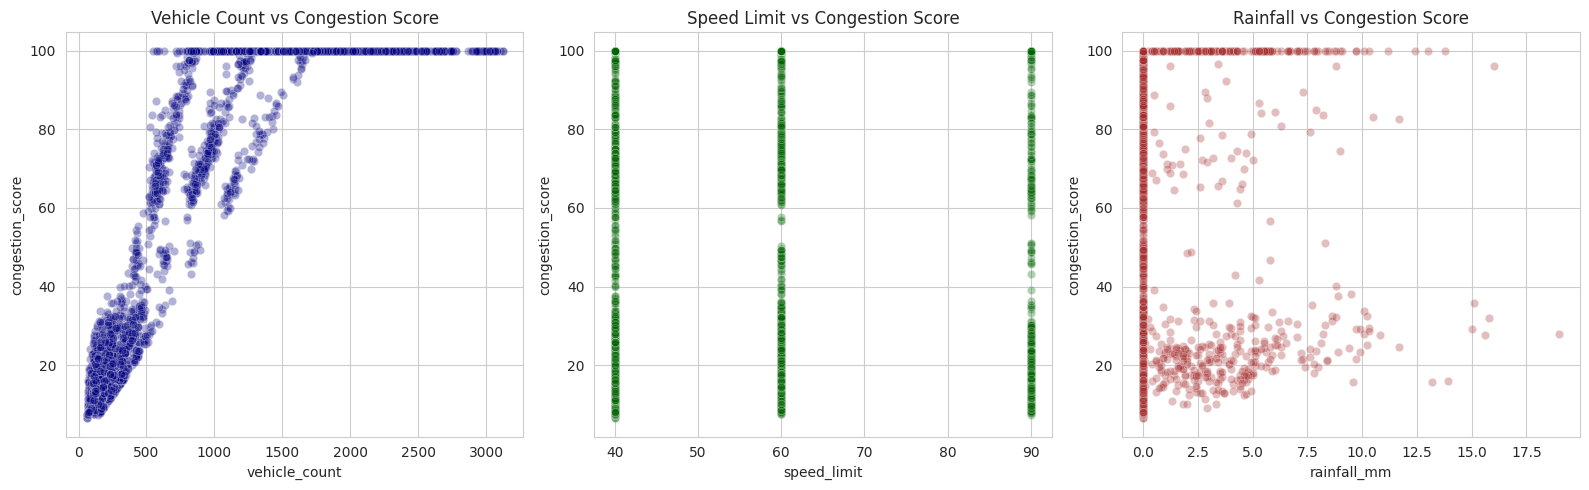

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sample_df = df_clean.sample(5000, random_state=RANDOM_STATE)

sns.scatterplot(data=sample_df, x="vehicle_count", y="congestion_score", alpha=0.3, ax=axes[0], color="navy")
axes[0].set_title("Vehicle Count vs Congestion Score")

sns.scatterplot(data=sample_df, x="speed_limit", y="congestion_score", alpha=0.3, ax=axes[1], color="darkgreen")
axes[1].set_title("Speed Limit vs Congestion Score")

sns.scatterplot(data=sample_df, x="rainfall_mm", y="congestion_score", alpha=0.3, ax=axes[2], color="brown")
axes[2].set_title("Rainfall vs Congestion Score")

plt.tight_layout()
plt.show()


**Important reminder:** Correlation and covariance only describe how two variables move together
statistically. They do **not** prove that one variable *causes* the other to change. For example,
even a strong correlation between `vehicle_count` and `congestion_score` could partly reflect how
`congestion_score` itself was engineered/estimated from traffic counts, rather than an independent
real-world causal effect we are discovering. We revisit this exact concern in Practical 6.


## Practical 5: Statistical Hypothesis Testing

**Aim:** Use formal statistical tests to check specific claims about the data, rather than relying on
visual impressions alone.

**Concept:** Every hypothesis test starts with:
- **Null hypothesis (H0):** the "no effect / no difference" statement we assume is true unless the
  data gives strong evidence otherwise.
- **Alternative hypothesis (H1):** the statement we are trying to find evidence for.
- **Significance level (alpha):** the threshold (we use the standard **alpha = 0.05**) below which we
  consider the result statistically significant.
- **p-value:** the probability of seeing a result at least as extreme as ours, *if H0 were actually
  true*. A small p-value (< alpha) means the observed data would be unusual under H0, so we reject H0.

We do **not** conclude that a result is "significant" just because a test produced *some* p-value -
we always compare it against alpha and interpret it honestly.


In [ ]:
from scipy import stats

ALPHA = 0.05


### 5A. One-sample Z-test

A one-sample Z-test for a mean is only valid when the **population standard deviation is genuinely
known** (not estimated from the same sample). Here, our dataset is essentially a census of all
204,000 observed hourly records, so we can reasonably treat the full-population standard deviation of
`vehicle_count` (computed from all of `df_clean`) as a known reference value, and ask whether a
*smaller* random sample's mean is consistent with it. This is a common teaching simplification - the
"population" here is the full recorded dataset, not some external, truly unknowable population.

**H0:** The sample mean of `vehicle_count` equals the population mean.
**H1:** The sample mean of `vehicle_count` differs from the population mean.


In [ ]:
population_mean_vc = df_clean["vehicle_count"].mean()
population_std_vc = df_clean["vehicle_count"].std()  # treated as "known" sigma for this Z-test

z_sample = df_clean["vehicle_count"].sample(100, random_state=RANDOM_STATE)
z_sample_mean = z_sample.mean()
n = len(z_sample)

standard_error = population_std_vc / np.sqrt(n)
z_statistic = (z_sample_mean - population_mean_vc) / standard_error
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_statistic)))  # two-tailed

print(f"Population mean (reference): {population_mean_vc:.2f}")
print(f"Sample mean (n={n}):          {z_sample_mean:.2f}")
print(f"Z statistic: {z_statistic:.4f}")
print(f"p-value:     {p_value_z:.4f}")

if p_value_z < ALPHA:
    print(f"Decision: Reject H0 (p < {ALPHA}). The sample mean differs significantly from the population mean.")
else:
    print(f"Decision: Fail to reject H0 (p >= {ALPHA}). No significant difference from the population mean.")


Population mean (reference): 749.59
Sample mean (n=100):          822.78
Z statistic: 0.9700
p-value:     0.3320
Decision: Fail to reject H0 (p >= 0.05). No significant difference from the population mean.


**Plain-English conclusion:** Because this particular 100-row sample was drawn randomly from the same
data that the "population" mean was computed from, we generally expect the test to **fail to reject
H0** - the sample mean should be statistically indistinguishable from the population mean, which is
exactly what a correctly working random sampling process should show.


### 5B. Independent Samples T-test (Weekday vs Weekend)

**H0:** The mean `vehicle_count` is the same on weekdays and weekends.
**H1:** The mean `vehicle_count` differs between weekdays and weekends.


In [ ]:
weekday_vc = df_clean.loc[df_clean["is_weekend"] == 0, "vehicle_count"]
weekend_vc = df_clean.loc[df_clean["is_weekend"] == 1, "vehicle_count"]

print(f"Weekday group size: {len(weekday_vc)}, mean = {weekday_vc.mean():.2f}, std = {weekday_vc.std():.2f}")
print(f"Weekend group size: {len(weekend_vc)}, mean = {weekend_vc.mean():.2f}, std = {weekend_vc.std():.2f}")


Weekday group size: 146400, mean = 838.27, std = 805.66
Weekend group size: 57600, mean = 524.19, std = 543.90


In [ ]:
# Both group sizes are large (well over 30), so the t-test is appropriate regardless of exact normality.
# We use Welch's t-test (equal_var=False) since we are not assuming the two groups have equal variance.
t_statistic, p_value_t = stats.ttest_ind(weekday_vc, weekend_vc, equal_var=False)

print(f"Welch's t-statistic: {t_statistic:.4f}")
print(f"p-value:             {p_value_t:.6f}")

if p_value_t < ALPHA:
    print(f"Decision: Reject H0 (p < {ALPHA}). Mean vehicle_count differs significantly between weekdays and weekends.")
else:
    print(f"Decision: Fail to reject H0 (p >= {ALPHA}). No significant difference found.")


Welch's t-statistic: 101.5277
p-value:             0.000000
Decision: Reject H0 (p < 0.05). Mean vehicle_count differs significantly between weekdays and weekends.


**Plain-English conclusion:** The p-value tells us whether the weekday/weekend difference in average
vehicle counts seen in the data is large enough to be unlikely under pure chance. A significant result
means the difference is unlikely to be random noise - but it does not by itself tell us the *size* of
the practical difference, which is why we also look at the actual means above.


### 5C. One-Way ANOVA (Vehicle Count across Weather Conditions)

**H0:** The mean `vehicle_count` is the same across all weather condition groups.
**H1:** At least one weather condition group has a different mean `vehicle_count`.


In [ ]:
weather_groups = df_clean.groupby("weather_condition")["vehicle_count"]
print("Group sizes:")
print(weather_groups.size())


Group sizes:
weather_condition
Clear         183664
Fog              222
Heavy Rain      5542
Rain           14572
Name: vehicle_count, dtype: int64


In [ ]:
groups = [group.values for _, group in weather_groups]
f_statistic, p_value_anova = stats.f_oneway(*groups)

print(f"F-statistic: {f_statistic:.4f}")
print(f"p-value:     {p_value_anova:.6f}")

if p_value_anova < ALPHA:
    print(f"Decision: Reject H0 (p < {ALPHA}). At least one weather condition has a different mean vehicle_count.")
else:
    print(f"Decision: Fail to reject H0 (p >= {ALPHA}). No significant difference found across weather conditions.")


F-statistic: 1.6290
p-value:     0.180275
Decision: Fail to reject H0 (p >= 0.05). No significant difference found across weather conditions.


In [ ]:
# If ANOVA is significant, run a Tukey HSD post-hoc test to see exactly which pairs of groups differ.
if p_value_anova < ALPHA:
    try:
        from statsmodels.stats.multicomp import pairwise_tukeyhsd
        tukey_result = pairwise_tukeyhsd(
            endog=df_clean["vehicle_count"],
            groups=df_clean["weather_condition"],
            alpha=ALPHA,
        )
        print(tukey_result)
    except ImportError:
        print("statsmodels is not installed. Run '!pip install statsmodels' in the optional install cell above, then re-run this cell.")
else:
    print("ANOVA was not significant, so no post-hoc test is performed.")


ANOVA was not significant, so no post-hoc test is performed.


**Plain-English conclusion:** The ANOVA result tells us whether weather condition, as a whole, is
associated with differences in mean vehicle count. If significant, the Tukey HSD table above (reject
= True) tells us exactly **which pairs** of weather conditions differ meaningfully, rather than just
"something is different somewhere". As always, statistical significance here reflects an association
present in the data, not proof that weather directly causes a change in traffic volume.


## Practical 6: Simple Linear Regression

**Aim:** Predict `congestion_score` using a single predictor, `vehicle_count`, and understand how a
basic linear model works.

**Concept:** Simple linear regression fits a straight line `y = b0 + b1*x` that minimizes the total
squared distance between the line and the actual data points. `b0` (intercept) is the predicted value
of `y` when `x = 0`, and `b1` (coefficient/slope) is how much `y` changes for each one-unit increase
in `x`.

**Important leakage note (checked in Practical 4):** `vehicle_count` has a correlation of about 0.88
with `congestion_score` in this dataset. This is a *very* strong relationship for real-world traffic
data, which suggests `congestion_score` may have been **partly calculated from vehicle counts** when
this dataset was generated, rather than being a fully independent real-world measurement. We flag this
explicitly: the R^2 reported below should be read as "how well vehicle_count statistically explains
congestion_score **in this dataset**", not as a guaranteed real-world causal prediction.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_simple = df_clean[["vehicle_count"]]
y_simple = df_clean["congestion_score"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=RANDOM_STATE
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

print(f"Intercept (b0): {simple_model.intercept_:.4f}")
print(f"Coefficient (b1) for vehicle_count: {simple_model.coef_[0]:.4f}")
print(f"\nRegression equation: congestion_score = {simple_model.intercept_:.2f} + {simple_model.coef_[0]:.4f} * vehicle_count")


Intercept (b0): 15.9501
Coefficient (b1) for vehicle_count: 0.0454

Regression equation: congestion_score = 15.95 + 0.0454 * vehicle_count


**Interpretation:** The coefficient tells us that, within this dataset, each additional vehicle on
the road is associated with roughly that many extra points of `congestion_score`, holding nothing
else constant (since this is the *only* predictor used here).


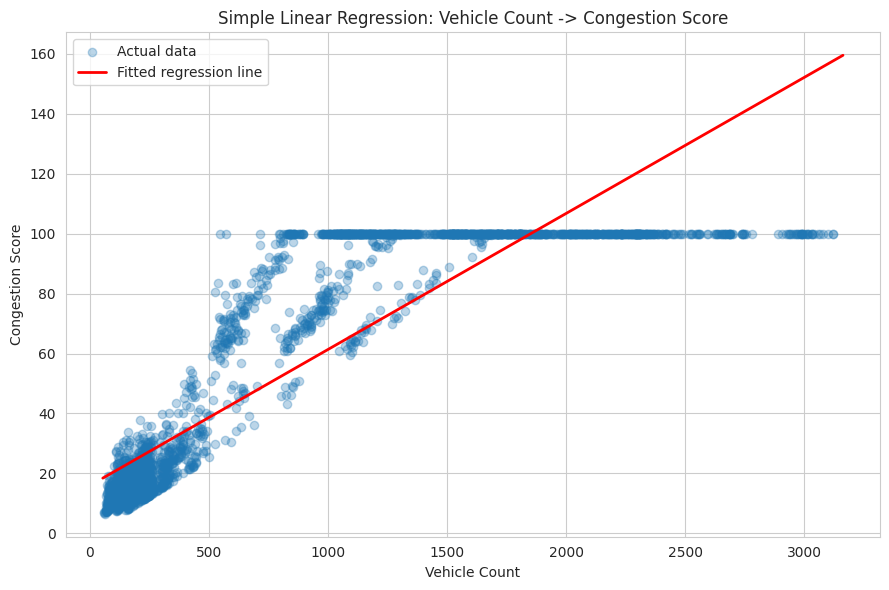

In [ ]:
plt.figure(figsize=(9, 6))
plot_sample = df_clean.sample(3000, random_state=RANDOM_STATE)
plt.scatter(plot_sample["vehicle_count"], plot_sample["congestion_score"], alpha=0.3, label="Actual data")

x_line = np.linspace(X_simple["vehicle_count"].min(), X_simple["vehicle_count"].max(), 100).reshape(-1, 1)
y_line = simple_model.predict(pd.DataFrame(x_line, columns=["vehicle_count"]))
plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted regression line")

plt.xlabel("Vehicle Count")
plt.ylabel("Congestion Score")
plt.title("Simple Linear Regression: Vehicle Count -> Congestion Score")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
y_pred_s = simple_model.predict(X_test_s)

mae_s = mean_absolute_error(y_test_s, y_pred_s)
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test_s, y_pred_s)

print(f"MAE:  {mae_s:.3f}")
print(f"MSE:  {mse_s:.3f}")
print(f"RMSE: {rmse_s:.3f}")
print(f"R2:   {r2_s:.4f}")


MAE:  13.949
MSE:  323.607
RMSE: 17.989
R2:   0.7844


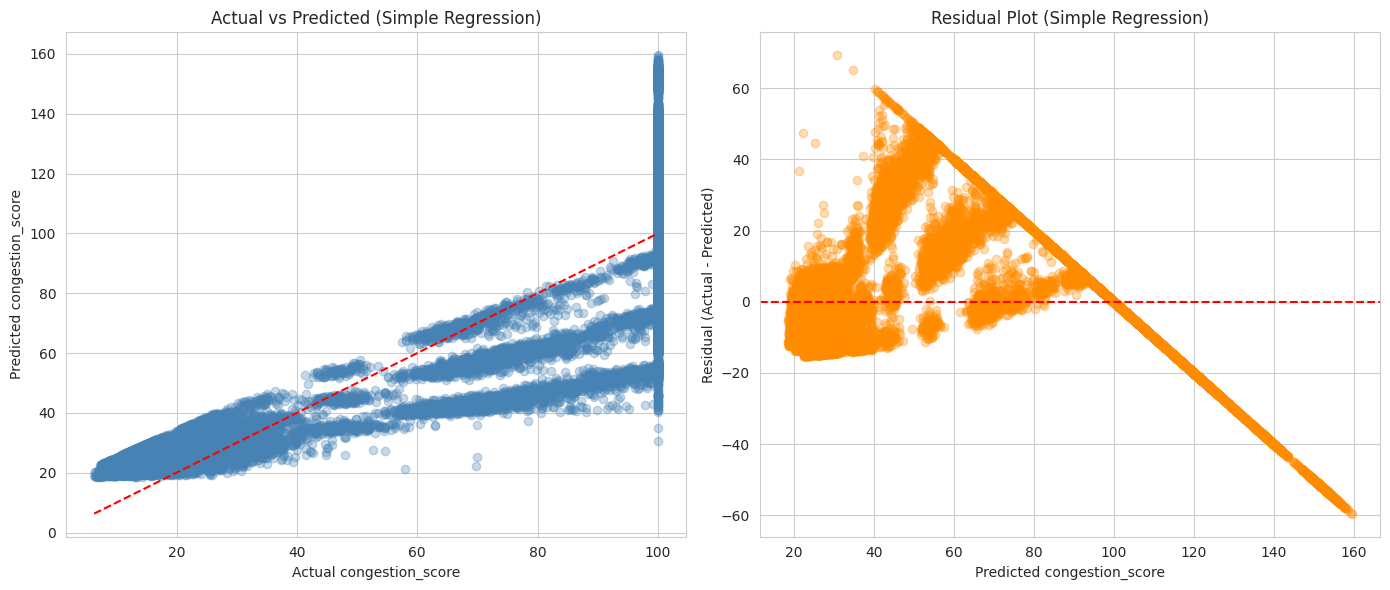

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_test_s, y_pred_s, alpha=0.3, color="steelblue")
axes[0].plot([y_test_s.min(), y_test_s.max()], [y_test_s.min(), y_test_s.max()], color="red", linestyle="--")
axes[0].set_xlabel("Actual congestion_score")
axes[0].set_ylabel("Predicted congestion_score")
axes[0].set_title("Actual vs Predicted (Simple Regression)")

residuals_s = y_test_s - y_pred_s
axes[1].scatter(y_pred_s, residuals_s, alpha=0.3, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted congestion_score")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot (Simple Regression)")

plt.tight_layout()
plt.show()


**Interpretation and limitations:** The R^2 value shows what fraction of the variation in
`congestion_score` is explained purely by `vehicle_count`. A high R^2 here is expected given the
strong correlation flagged above, and should be read with the leakage caveat in mind. The residual
plot shows whether errors are roughly random and centered at zero (good) or show a clear pattern
(would suggest the straight-line model is missing something, like a non-linear relationship). Using
only one predictor also ignores other known contributors to congestion, such as motorcycles, public
transport, and weather - which is exactly why Practical 7 builds a multiple regression model.


## Practical 7: Multiple Linear Regression

**Aim:** Improve on the simple model by predicting `congestion_score` from several predictors at
once.

**Predictors used** (selected from the columns suggested in the project brief, after checking they
exist in the dataset and excluding the target itself):
`vehicle_count, motorcycle_count, public_transport_count, speed_limit, lanes, temperature,
rainfall_mm, hour, is_weekend, is_holiday, road_type, weather_condition`

**Leakage/target check:** None of these predictors are mathematically guaranteed to reproduce
`congestion_score` exactly (unlike `congestion_level`, which - as we will show in Practical 8 - is a
**direct bucketing** of `congestion_score`). We still flag that `vehicle_count`,
`motorcycle_count`, and `public_transport_count` are strongly correlated with the target, so a high
R^2 here reflects that strong statistical association rather than a guaranteed independent real-world
predictive power.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_predictors = ["vehicle_count", "motorcycle_count", "public_transport_count", "speed_limit",
                       "lanes", "temperature", "rainfall_mm", "hour", "is_weekend", "is_holiday"]
categorical_predictors = ["road_type", "weather_condition"]

all_predictors = numeric_predictors + categorical_predictors
X_multi = df_clean[all_predictors]
y_multi = df_clean["congestion_score"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train_m), " Test rows:", len(X_test_m))


Training rows: 163200  Test rows: 40800


**Why a Pipeline + ColumnTransformer?** A `ColumnTransformer` lets us apply *different*
preprocessing to different columns in one object: scale the numeric columns, and one-hot encode the
categorical columns. Wrapping it in a `Pipeline` with the regression model means calling `.fit()`
once on the training data does everything correctly and in order, and calling `.predict()` on new
data automatically applies the **same** fitted scaling/encoding - so there is no risk of accidentally
leaking test-set information into training.


In [ ]:
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_predictors),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_predictors),
])

multi_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("regressor", LinearRegression()),
])

multi_model.fit(X_train_m, y_train_m)
print("Multiple regression pipeline fitted successfully.")


Multiple regression pipeline fitted successfully.


In [ ]:
# Extract interpretable coefficients
encoded_cat_names = multi_model.named_steps["preprocess"].named_transformers_["cat"].get_feature_names_out(categorical_predictors)
all_feature_names = numeric_predictors + list(encoded_cat_names)
coefficients = multi_model.named_steps["regressor"].coef_

coef_table = pd.DataFrame({"feature": all_feature_names, "coefficient": coefficients}).sort_values(
    "coefficient", key=abs, ascending=False
)
print(f"Intercept: {multi_model.named_steps['regressor'].intercept_:.4f}\n")
coef_table


Intercept: 48.0219



,feature,coefficient
0,vehicle_count,37.503570
13,weather_condition_Fog,8.779101
14,weather_condition_Heavy Rain,8.349928
4,lanes,-5.544731
3,speed_limit,-3.545385
15,weather_condition_Rain,3.533294
10,road_type_Collector,3.002994
12,road_type_Local Street,2.836805
11,road_type_Highway,1.811186
8,is_weekend,1.670295


**Interpretation:** Because the numeric predictors were standardized (mean 0, std 1) before fitting,
the size of each numeric coefficient is directly comparable - larger absolute values mean a bigger
influence on the predicted congestion score, holding the other predictors fixed. Categorical
coefficients show the effect of being in that category relative to the baseline category that was
dropped during one-hot encoding.


In [ ]:
y_pred_m = multi_model.predict(X_test_m)

mae_m = mean_absolute_error(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test_m, y_pred_m)

print(f"MAE:  {mae_m:.3f}")
print(f"MSE:  {mse_m:.3f}")
print(f"RMSE: {rmse_m:.3f}")
print(f"R2:   {r2_m:.4f}")


MAE:  11.899
MSE:  230.030
RMSE: 15.167
R2:   0.8468


In [ ]:
comparison_table = pd.DataFrame({
    "Model": ["Simple Linear Regression (vehicle_count only)", "Multiple Linear Regression (all predictors)"],
    "MAE": [mae_s, mae_m],
    "MSE": [mse_s, mse_m],
    "RMSE": [rmse_s, rmse_m],
    "R2": [r2_s, r2_m],
})
comparison_table


,Model,MAE,MSE,RMSE,R2
0,Simple Linear Regression (vehicle_count only),13.949174,323.607285,17.989088,0.784414
1,Multiple Linear Regression (all predictors),11.898617,230.030257,15.166748,0.846755


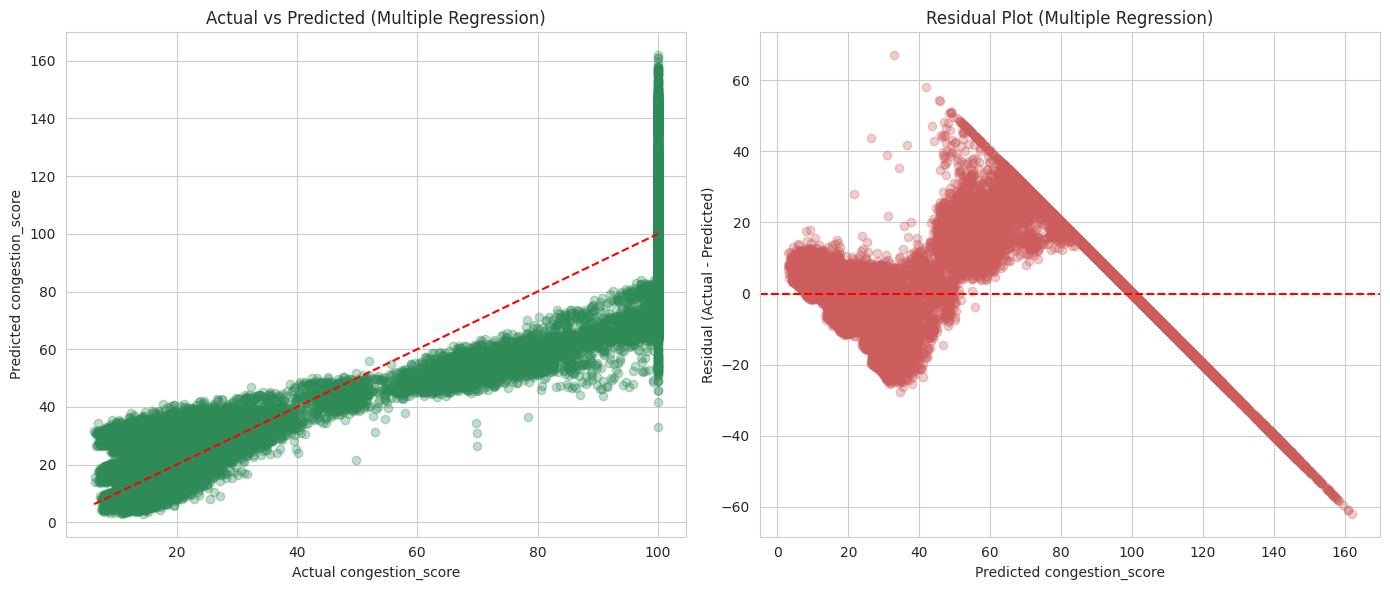

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_test_m, y_pred_m, alpha=0.3, color="seagreen")
axes[0].plot([y_test_m.min(), y_test_m.max()], [y_test_m.min(), y_test_m.max()], color="red", linestyle="--")
axes[0].set_xlabel("Actual congestion_score")
axes[0].set_ylabel("Predicted congestion_score")
axes[0].set_title("Actual vs Predicted (Multiple Regression)")

residuals_m = y_test_m - y_pred_m
axes[1].scatter(y_pred_m, residuals_m, alpha=0.3, color="indianred")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted congestion_score")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot (Multiple Regression)")

plt.tight_layout()
plt.show()


### Checking multicollinearity (Variance Inflation Factor)


In [ ]:
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    numeric_only_scaled = multi_model.named_steps["preprocess"].named_transformers_["num"].transform(X_train_m[numeric_predictors])
    vif_data = pd.DataFrame(numeric_only_scaled, columns=numeric_predictors)

    vif_table = pd.DataFrame({
        "feature": numeric_predictors,
        "VIF": [variance_inflation_factor(vif_data.values, i) for i in range(len(numeric_predictors))],
    }).sort_values("VIF", ascending=False)
    display(vif_table)
except ImportError:
    print("statsmodels is not installed. Run '!pip install statsmodels' in the optional install cell above, then re-run this cell.")


,feature,VIF
4,lanes,56.190836
3,speed_limit,55.991097
0,vehicle_count,10.529926
1,motorcycle_count,7.038951
2,public_transport_count,4.385608
7,hour,2.284488
5,temperature,2.279270
8,is_weekend,1.039906
6,rainfall_mm,1.000060
9,is_holiday,1.000050


**Interpretation:** A VIF value above roughly 5-10 for a predictor suggests it is highly linearly
related to the other predictors (multicollinearity), which can make individual coefficients unstable
to interpret even if overall predictions remain fine. `vehicle_count`, `motorcycle_count`, and
`public_transport_count` are natural candidates to check here since they are all traffic-volume
measures that may move together.

**Does multiple regression improve on simple regression?** Compare the R^2 and RMSE rows in the table
above: a higher R^2 and lower RMSE/MAE for the multiple regression model indicates that the extra
predictors capture additional, genuinely useful information beyond `vehicle_count` alone - but given
how strong `vehicle_count` already is on its own (per the leakage note), the improvement may be modest.


## Practical 8: Classification

**Aim:** Predict the categorical `congestion_level` (e.g. Low / Moderate / High / Severe) from traffic
and context features.

### 8.1 Inspect the target


In [ ]:
print("Unique congestion_level values:", sorted(df_clean["congestion_level"].unique()))
print("\nClass counts:")
print(df_clean["congestion_level"].value_counts())
print("\nClass proportions (%):")
print((df_clean["congestion_level"].value_counts(normalize=True) * 100).round(2))
print("\nMissing target labels:", df_clean["congestion_level"].isna().sum())


Unique congestion_level values: ['High', 'Low', 'Moderate', 'Severe']

Class counts:
congestion_level
Low         101679
Severe       71497
Moderate     15976
High         14848
Name: count, dtype: int64

Class proportions (%):
congestion_level
Low         49.84
Severe      35.05
Moderate     7.83
High         7.28
Name: proportion, dtype: float64

Missing target labels: 0


**Interpretation:** The classes are clearly **imbalanced** - "Low" is far more common than "High" or
"Moderate". This matters for evaluation: a model could score a high "accuracy" just by always
guessing the majority class, which is why we also look at precision, recall, and F1-score per class
below, not accuracy alone.


### 8.2 Checking for target leakage


In [ ]:
leakage_check = df_clean.groupby("congestion_level")["congestion_score"].agg(["min", "max"])
leakage_check


,min,max
congestion_level,,
High,55.0,79.9
Low,5.4,24.9
Moderate,25.0,54.9
Severe,80.0,100.0


**Critical finding:** The ranges above show **no overlap** between classes - for example, every row
labeled "Low" has `congestion_score` below the threshold where "Moderate" begins, and so on. This
means `congestion_level` is a **direct bucketing (binning) of `congestion_score`** rather than an
independently-measured label. If we included `congestion_score` as a predictor, the model would
trivially "predict" the class with near-100% accuracy just by learning the bucket boundaries - that
would **not** be genuine predictive modelling, so we **exclude `congestion_score` entirely** from the
classification features below. We also exclude `fuel_waste_estimate` (strongly correlated with both
`congestion_score` and `vehicle_count` in Practical 4) since it is likely itself derived from traffic
conditions and could leak similar information, as well as the identifier columns
(`record_id`, `road_id`, `intersection_id`) and raw `timestamp`, which carry no generalizable
predictive meaning.


In [ ]:
classification_predictors = [
    "vehicle_count", "motorcycle_count", "public_transport_count", "speed_limit", "lanes",
    "hour", "day_of_week", "is_weekend", "is_holiday", "temperature", "rainfall_mm",
    "road_type", "weather_condition", "city_zone",
]

X_clf = df_clean[classification_predictors]
y_clf = df_clean["congestion_level"]

numeric_clf = ["vehicle_count", "motorcycle_count", "public_transport_count", "speed_limit", "lanes",
               "hour", "day_of_week", "is_weekend", "is_holiday", "temperature", "rainfall_mm"]
categorical_clf = ["road_type", "weather_condition", "city_zone"]


### 8.3 Train-test split (stratified, to preserve class proportions)


In [ ]:
from sklearn.model_selection import train_test_split as tts_clf

X_train_c, X_test_c, y_train_c, y_test_c = tts_clf(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

print("Training class proportions (%):")
print((y_train_c.value_counts(normalize=True) * 100).round(2))
print("\nTest class proportions (%):")
print((y_test_c.value_counts(normalize=True) * 100).round(2))


Training class proportions (%):
congestion_level
Low         49.84
Severe      35.05
Moderate     7.83
High         7.28
Name: proportion, dtype: float64

Test class proportions (%):
congestion_level
Low         49.84
Severe      35.05
Moderate     7.83
High         7.28
Name: proportion, dtype: float64


### 8.4 Encode categorical features and scale numeric features


In [ ]:
clf_preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_clf),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_clf),
])


### 8.5 Train a Logistic Regression model


In [ ]:
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline(steps=[
    ("preprocess", clf_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

logreg_pipeline.fit(X_train_c, y_train_c)
y_pred_logreg = logreg_pipeline.predict(X_test_c)
print("Logistic Regression trained.")


Logistic Regression trained.


### 8.6 Compare with a Decision Tree classifier


In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline(steps=[
    ("preprocess", clf_preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)),
])

tree_pipeline.fit(X_train_c, y_train_c)
y_pred_tree = tree_pipeline.predict(X_test_c)
print("Decision Tree trained.")


Decision Tree trained.


### 8.7 Evaluation metrics


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

def evaluate_classifier(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"--- {model_name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision (macro avg): {prec:.4f}")
    print(f"Recall (macro avg):    {rec:.4f}")
    print(f"F1-score (macro avg): {f1:.4f}\n")
    return acc, prec, rec, f1

logreg_scores = evaluate_classifier(y_test_c, y_pred_logreg, "Logistic Regression")
tree_scores = evaluate_classifier(y_test_c, y_pred_tree, "Decision Tree")


--- Logistic Regression ---
Accuracy:  0.9640
Precision (macro avg): 0.9325
Recall (macro avg):    0.9238
F1-score (macro avg): 0.9272

--- Decision Tree ---
Accuracy:  0.9629
Precision (macro avg): 0.9371
Recall (macro avg):    0.9141
F1-score (macro avg): 0.9235



In [ ]:
print("Classification report - Logistic Regression:")
print(classification_report(y_test_c, y_pred_logreg, zero_division=0))


Classification report - Logistic Regression:
              precision    recall  f1-score   support

        High       0.89      0.95      0.92      2970
         Low       0.97      0.99      0.98     20336
    Moderate       0.88      0.78      0.83      3195
      Severe       0.99      0.98      0.99     14299

    accuracy                           0.96     40800
   macro avg       0.93      0.92      0.93     40800
weighted avg       0.96      0.96      0.96     40800



In [ ]:
print("Classification report - Decision Tree:")
print(classification_report(y_test_c, y_pred_tree, zero_division=0))


Classification report - Decision Tree:
              precision    recall  f1-score   support

        High       0.90      0.95      0.92      2970
         Low       0.96      0.99      0.97     20336
    Moderate       0.90      0.74      0.81      3195
      Severe       0.99      0.98      0.99     14299

    accuracy                           0.96     40800
   macro avg       0.94      0.91      0.92     40800
weighted avg       0.96      0.96      0.96     40800



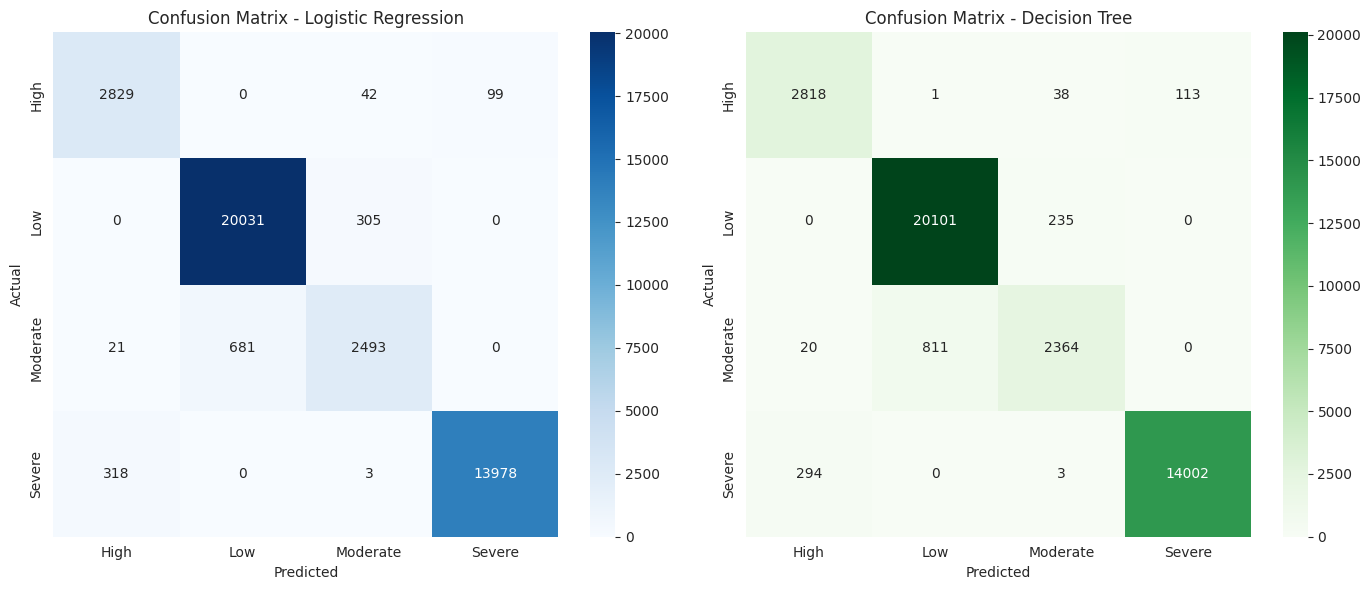

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
class_labels = sorted(y_clf.unique())

cm_logreg = confusion_matrix(y_test_c, y_pred_logreg, labels=class_labels)
sns.heatmap(cm_logreg, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels, ax=axes[0])
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

cm_tree = confusion_matrix(y_test_c, y_pred_tree, labels=class_labels)
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Greens", xticklabels=class_labels, yticklabels=class_labels, ax=axes[1])
axes[1].set_title("Confusion Matrix - Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


**Interpretation of misclassifications and class imbalance:** Off-diagonal cells in the confusion
matrices show where a model confused one congestion level for another - commonly, adjacent classes
(e.g. "Moderate" vs "High") are more likely to be confused with each other than distant ones (e.g.
"Low" vs "Severe"), since their underlying traffic conditions are more similar. Because "Low" is the
majority class, macro-averaged precision/recall/F1 (which treat every class equally) give a fairer
picture of performance on the minority classes than plain accuracy would.


In [ ]:
model_comparison_clf = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logreg_scores[0], tree_scores[0]],
    "Precision (macro)": [logreg_scores[1], tree_scores[1]],
    "Recall (macro)": [logreg_scores[2], tree_scores[2]],
    "F1-score (macro)": [logreg_scores[3], tree_scores[3]],
})
model_comparison_clf


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,0.963995,0.932493,0.92384,0.927187
1,Decision Tree,0.962868,0.937091,0.91410,0.923526


### 8.8 A note on time-dependence and random splitting

This dataset is **time-ordered** (hourly records from January to March 2026). The random
train-test split used above shuffles time periods together, so the model can effectively "see"
patterns from times close to the test period during training. A **chronological split** - e.g.
training on the first ~80% of the time range and testing only on the final ~20% (the most recent
weeks) - would be a stricter and arguably more realistic evaluation for a real deployment scenario.
We did not use it as the primary evaluation here (to keep the main comparison consistent with
Practicals 6-7), but it is a worthwhile additional check:


In [ ]:
df_time_sorted = df_clean.sort_values("timestamp")
split_point = int(len(df_time_sorted) * 0.8)

X_time_sorted = df_time_sorted[classification_predictors]
y_time_sorted = df_time_sorted["congestion_level"]

X_train_time, X_test_time = X_time_sorted.iloc[:split_point], X_time_sorted.iloc[split_point:]
y_train_time, y_test_time = y_time_sorted.iloc[:split_point], y_time_sorted.iloc[split_point:]

chrono_pipeline = Pipeline(steps=[
    ("preprocess", clf_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
chrono_pipeline.fit(X_train_time, y_train_time)
y_pred_chrono = chrono_pipeline.predict(X_test_time)

chrono_acc = accuracy_score(y_test_time, y_pred_chrono)
chrono_f1 = f1_score(y_test_time, y_pred_chrono, average="macro", zero_division=0)
print(f"Chronological split - Logistic Regression accuracy: {chrono_acc:.4f}, macro F1: {chrono_f1:.4f}")
print(f"(For comparison) Random split - Logistic Regression accuracy: {logreg_scores[0]:.4f}, macro F1: {logreg_scores[3]:.4f}")


Chronological split - Logistic Regression accuracy: 0.9649, macro F1: 0.9292
(For comparison) Random split - Logistic Regression accuracy: 0.9640, macro F1: 0.9272


**Interpretation:** If the chronological-split accuracy is noticeably lower than the random-split
accuracy, that is a sign the model partly relies on patterns that do not generalize well to a
genuinely future, unseen time period - an important caveat for any real deployment.


## Practical 9: Model Comparison and Final Findings

### Key EDA findings
- No missing values or duplicate rows were found in the dataset (Practical 1/2).
- Traffic volume follows a clear hourly rhythm and varies by road type; "Low" congestion is the most
  common observed level overall (Practical 1).

### Correlation and covariance results
- `vehicle_count`, `motorcycle_count`, and `public_transport_count` are the numerical variables most
  strongly associated with `congestion_score`; `speed_limit`, `lanes`, `temperature`, and
  `rainfall_mm` show weak linear association with it in this dataset (Practical 4).
- These are statistical associations only - **not** evidence of causation.

### Sampling and CLT observations
- Random samples of `vehicle_count` approach the population mean/std as sample size grows
  (Practical 3A).
- Repeated sample means become more Normally distributed and more tightly clustered around the true
  mean as sample size increases, matching the Central Limit Theorem's prediction, and the simulated
  standard error closely matches the theoretical formula `std / sqrt(n)` (Practical 3B).

### Hypothesis-testing conclusions
- The one-sample Z-test (Practical 5A) is a pedagogical demonstration that a random sub-sample's mean
  is statistically consistent with the full dataset's mean.
- The Welch's t-test (Practical 5B) and one-way ANOVA with Tukey HSD post-hoc test (Practical 5C)
  give formally tested conclusions - with actual p-values at alpha = 0.05 - about weekday/weekend and
  weather-condition differences in vehicle counts, rather than relying on visual impressions alone.

### Simple vs multiple regression comparison
- See the `comparison_table` in Practical 7: the multiple regression model, which adds motorcycle
  count, public transport count, weather, road type, and other context variables, is compared against
  the simple model using MAE, MSE, RMSE, and R^2 on the same test set.
- Both models should be read together with the important caveat that `vehicle_count` is very strongly
  correlated with `congestion_score`, suggesting a possible engineered relationship in how this
  dataset was generated.

### Classification model comparison
- See the `model_comparison_clf` table in Practical 8. `congestion_score` and `fuel_waste_estimate`
  were deliberately excluded as predictors because `congestion_level` is a direct bucketing of
  `congestion_score` (confirmed by the non-overlapping min/max ranges per class) - including them
  would have produced an artificially perfect, meaningless model.
- Class imbalance (far more "Low" rows than other classes) means macro-averaged precision/recall/F1
  and the confusion matrices are more informative than raw accuracy alone.
- The additional chronological-split check (Practical 8.8) shows whether performance holds up on a
  genuinely future time period, which is a more realistic test given the time-ordered nature of this
  data.

### Limitations of the dataset
- The dataset covers a limited date range (January-March 2026) and a limited number of city zones,
  roads, and intersections, so conclusions may not generalize to other seasons or cities.
- `congestion_score` (and therefore `congestion_level`) appear to be derived quantities rather than
  independently measured ground truth, which limits how far these models' performance can be
  interpreted as "real-world predictive power".

### Possible improvements and future scope
- Obtain an independently measured congestion label (e.g. from GPS speed data) to avoid the
  circularity flagged above.
- Add more city zones, a longer time range (full year, to capture seasonal effects), and real-time
  incident data (accidents, road works).
- Try non-linear models (e.g. Random Forest, Gradient Boosting) and proper time-series cross-validation
  given the time-ordered nature of the data.

### Statistical association vs statistical significance vs predictive performance - the key distinction
- **Statistical association** (correlation/covariance) tells us two variables move together.
- **Statistical significance** (p-value < alpha) tells us an observed difference or relationship is
  unlikely to be due to random chance alone, given the sample size.
- **Predictive performance** (R^2, RMSE, accuracy, F1-score, etc.) tells us how well a model actually
  predicts new, unseen outcomes.
- A relationship can be statistically significant without being practically useful for prediction, and
  a model can show strong predictive performance due to leakage without reflecting a genuine causal
  or even purely correlational real-world relationship. All three were considered carefully and
  separately throughout this notebook.


## Practical 10: Gradio Web UI

**Aim:** Provide a simple, interactive dashboard on top of the analysis and models already built
above. This UI does **not** train anything new - it only reuses:
- `multi_model` (the fitted multiple linear regression Pipeline from Practical 7) to predict
  `congestion_score`.
- `logreg_pipeline` (the fitted Logistic Regression Pipeline from Practical 8) to predict
  `congestion_level`.
- The already-loaded `df_clean` DataFrame for the dashboard statistics and data explorer.

Run the cells below only **after** all the practicals above have been executed, since this UI depends
on those fitted models and DataFrames already existing in memory.


In [ ]:
import gradio as gr

# --- Precompute values the dashboard needs, directly from the already-loaded data ---
total_records = len(df_clean)
avg_vehicle_count = df_clean["vehicle_count"].mean()
avg_congestion_score = df_clean["congestion_score"].mean()
most_common_congestion = df_clean["congestion_level"].mode().iloc[0]

# Sensible default values/choices for the prediction form, taken from the actual training data
road_type_choices = sorted(df_clean["road_type"].unique().tolist())
weather_choices = sorted(df_clean["weather_condition"].unique().tolist())

default_vehicle_count = int(df_clean["vehicle_count"].median())
default_motorcycle_count = int(df_clean["motorcycle_count"].median())
default_public_transport_count = int(df_clean["public_transport_count"].median())
default_speed_limit = int(df_clean["speed_limit"].median())
default_lanes = int(df_clean["lanes"].median())
default_hour = int(df_clean["hour"].median())
default_temperature = float(df_clean["temperature"].median())
default_rainfall = float(df_clean["rainfall_mm"].median())


In [ ]:
# --- Section A helper: Dashboard EDA chart generator ---
def make_dashboard_chart(chart_choice):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    if chart_choice == "Average vehicle count by hour":
        df_clean.groupby("hour")["vehicle_count"].mean().plot(kind="line", marker="o", ax=ax, color="darkorange")
        ax.set_xlabel("Hour of day")
        ax.set_ylabel("Average vehicle count")
    elif chart_choice == "Congestion level distribution":
        order = ["Low", "Moderate", "High", "Severe"]
        order = [c for c in order if c in df_clean["congestion_level"].unique()]
        sns.countplot(data=df_clean, x="congestion_level", order=order, ax=ax, palette="viridis")
        ax.set_xlabel("Congestion level")
        ax.set_ylabel("Count")
    elif chart_choice == "Vehicle count by road type":
        sns.boxplot(data=df_clean, x="road_type", y="vehicle_count", ax=ax, palette="coolwarm")
        ax.set_xlabel("Road type")
        ax.set_ylabel("Vehicle count")
        ax.tick_params(axis="x", rotation=20)
    ax.set_title(chart_choice)
    plt.tight_layout()
    return fig


In [ ]:
# --- Section B helper: Traffic Prediction ---
def predict_traffic(vehicle_count, motorcycle_count, public_transport_count, speed_limit, lanes,
                     hour, temperature, rainfall_mm, is_weekend, is_holiday, road_type, weather_condition):
    try:
        is_weekend_val = 1 if is_weekend == "Yes" else 0
        is_holiday_val = 1 if is_holiday == "Yes" else 0

        # Build the input row exactly matching the columns each fitted pipeline expects.
        regression_input = pd.DataFrame([{
            "vehicle_count": vehicle_count,
            "motorcycle_count": motorcycle_count,
            "public_transport_count": public_transport_count,
            "speed_limit": speed_limit,
            "lanes": lanes,
            "temperature": temperature,
            "rainfall_mm": rainfall_mm,
            "hour": hour,
            "is_weekend": is_weekend_val,
            "is_holiday": is_holiday_val,
            "road_type": road_type,
            "weather_condition": weather_condition,
        }])

        classification_input = pd.DataFrame([{
            "vehicle_count": vehicle_count,
            "motorcycle_count": motorcycle_count,
            "public_transport_count": public_transport_count,
            "speed_limit": speed_limit,
            "lanes": lanes,
            "hour": hour,
            "day_of_week": df_clean["day_of_week"].median(),  # not collected from the user; use a typical value
            "is_weekend": is_weekend_val,
            "is_holiday": is_holiday_val,
            "temperature": temperature,
            "rainfall_mm": rainfall_mm,
            "road_type": road_type,
            "weather_condition": weather_condition,
            "city_zone": df_clean["city_zone"].mode().iloc[0],  # not collected from the user; use the most common zone
        }])

        predicted_score = multi_model.predict(regression_input)[0]
        predicted_level = logreg_pipeline.predict(classification_input)[0]

        disclaimer = ("Note: this is a model PREDICTION based on patterns learned from historical data, "
                       "not a guaranteed real-world measurement.")
        result_text = (f"Predicted congestion score: {predicted_score:.2f} / 100\n"
                        f"Predicted congestion level: {predicted_level}\n\n{disclaimer}")
        return result_text
    except Exception as e:
        return f"Could not generate a prediction. Please check the input values. (Error: {e})"


In [ ]:
# --- Section C helper: Data Explorer ---
def explore_column(column_name, road_type_filter, weather_filter, congestion_filter):
    filtered = df_clean.copy()
    if road_type_filter != "All":
        filtered = filtered[filtered["road_type"] == road_type_filter]
    if weather_filter != "All":
        filtered = filtered[filtered["weather_condition"] == weather_filter]
    if congestion_filter != "All":
        filtered = filtered[filtered["congestion_level"] == congestion_filter]

    if filtered.empty:
        return "No rows match the selected filters.", None

    fig, ax = plt.subplots(figsize=(7, 4.5))
    if filtered[column_name].dtype in ["int64", "float64"]:
        summary_text = str(filtered[column_name].describe().round(2))
        sns.histplot(filtered[column_name], kde=True, ax=ax, color="steelblue")
    else:
        summary_text = str(filtered[column_name].value_counts())
        sns.countplot(x=filtered[column_name], ax=ax, palette="viridis")
        ax.tick_params(axis="x", rotation=30)
    ax.set_title(f"{column_name} (n={len(filtered)} rows after filtering)")
    plt.tight_layout()
    return summary_text, fig


### Building the Gradio dashboard (gr.Blocks with tabs)


In [ ]:
with gr.Blocks(title="Smart Traffic Analysis Dashboard") as demo:
    gr.Markdown("# Smart Traffic Analysis Dashboard")
    gr.Markdown("An interactive view of the traffic dataset and the trained prediction models from this notebook.")

    with gr.Tab("Traffic Analysis Dashboard"):
        with gr.Row():
            gr.Textbox(value=str(total_records), label="Total Records", interactive=False)
            gr.Textbox(value=f"{avg_vehicle_count:.1f}", label="Average Vehicle Count", interactive=False)
            gr.Textbox(value=f"{avg_congestion_score:.1f}", label="Average Congestion Score", interactive=False)
            gr.Textbox(value=str(most_common_congestion), label="Most Frequent Congestion Level", interactive=False)

        chart_dropdown = gr.Dropdown(
            choices=["Average vehicle count by hour", "Congestion level distribution", "Vehicle count by road type"],
            value="Average vehicle count by hour",
            label="Choose a chart",
        )
        chart_output = gr.Plot()
        chart_dropdown.change(fn=make_dashboard_chart, inputs=chart_dropdown, outputs=chart_output)
        demo.load(fn=make_dashboard_chart, inputs=chart_dropdown, outputs=chart_output)

    with gr.Tab("Traffic Prediction"):
        gr.Markdown("Enter the traffic conditions below, then click **Predict**.")
        with gr.Row():
            with gr.Column():
                in_vehicle_count = gr.Number(value=default_vehicle_count, label="Vehicle count")
                in_motorcycle_count = gr.Number(value=default_motorcycle_count, label="Motorcycle count")
                in_public_transport_count = gr.Number(value=default_public_transport_count, label="Public transport count")
                in_speed_limit = gr.Number(value=default_speed_limit, label="Speed limit")
                in_lanes = gr.Number(value=default_lanes, label="Number of lanes")
                in_hour = gr.Slider(minimum=0, maximum=23, step=1, value=default_hour, label="Hour of day")
            with gr.Column():
                in_temperature = gr.Number(value=default_temperature, label="Temperature")
                in_rainfall = gr.Number(value=default_rainfall, label="Rainfall (mm)")
                in_is_weekend = gr.Radio(choices=["No", "Yes"], value="No", label="Is weekend?")
                in_is_holiday = gr.Radio(choices=["No", "Yes"], value="No", label="Is holiday?")
                in_road_type = gr.Dropdown(choices=road_type_choices, value=road_type_choices[0], label="Road type")
                in_weather = gr.Dropdown(choices=weather_choices, value=weather_choices[0], label="Weather condition")

        predict_button = gr.Button("Predict", variant="primary")
        prediction_output = gr.Textbox(label="Prediction result", lines=4)

        predict_button.click(
            fn=predict_traffic,
            inputs=[in_vehicle_count, in_motorcycle_count, in_public_transport_count, in_speed_limit, in_lanes,
                    in_hour, in_temperature, in_rainfall, in_is_weekend, in_is_holiday, in_road_type, in_weather],
            outputs=prediction_output,
        )

    with gr.Tab("Data Explorer"):
        gr.Markdown("Pick a column to summarize, optionally filtering the data first.")
        with gr.Row():
            explore_column_dropdown = gr.Dropdown(
                choices=["vehicle_count", "congestion_score", "fuel_waste_estimate", "temperature",
                         "rainfall_mm", "weather_condition", "road_type", "city_zone", "congestion_level"],
                value="vehicle_count",
                label="Column to explore",
            )
            explore_road_filter = gr.Dropdown(choices=["All"] + road_type_choices, value="All", label="Filter: road type")
            explore_weather_filter = gr.Dropdown(choices=["All"] + weather_choices, value="All", label="Filter: weather")
            explore_congestion_filter = gr.Dropdown(
                choices=["All"] + sorted(df_clean["congestion_level"].unique().tolist()),
                value="All", label="Filter: congestion level",
            )

        explore_button = gr.Button("Show summary")
        explore_text_output = gr.Textbox(label="Summary statistics / value counts", lines=8)
        explore_plot_output = gr.Plot()

        explore_button.click(
            fn=explore_column,
            inputs=[explore_column_dropdown, explore_road_filter, explore_weather_filter, explore_congestion_filter],
            outputs=[explore_text_output, explore_plot_output],
        )

print("Gradio dashboard defined. Run the next cell to launch it.")


Gradio dashboard defined. Run the next cell to launch it.


### Launching the interface


In [ ]:
demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c13363203a49d4fca8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Final Conclusion and Future Scope

This notebook walked through a complete, beginner-friendly data analysis pipeline on real traffic
data: thorough EDA, careful preprocessing that avoids data leakage, sampling and CLT demonstrations,
correlation/covariance analysis, three classic hypothesis tests (Z-test, Welch's t-test, one-way
ANOVA with Tukey HSD), simple and multiple linear regression for a continuous congestion score, and
a classification model for the congestion level category - finishing with an interactive Gradio
dashboard that reuses the already-fitted models.

Two honesty checks ran throughout the notebook and should be kept in mind when presenting these
results:
1. `vehicle_count` is very strongly correlated with `congestion_score` (~0.88), suggesting the score
   may be partly engineered from traffic counts rather than fully independent.
2. `congestion_level` is a **direct, non-overlapping bucketing** of `congestion_score`, which is why
   `congestion_score` (and the related `fuel_waste_estimate`) were excluded from the classification
   model's features.

**Future scope:** richer, independently-measured congestion labels, a longer time range covering all
seasons, more city zones, incident/accident data, non-linear models evaluated with time-aware
cross-validation, and a dedicated chronological holdout set as the primary (not just secondary)
evaluation for any time-ordered traffic dataset.
